---
# 实验3. 回归分析

**目标：**
- 掌握线性回归和相关分析等技术的应用。

**数据：**
- Real estate.csv (exercises/data/linear_regression/Real estate.csv);
- 三江源国家公园矢量边界数据（exercises/data/SanJiangYuan/map/boua.shp）；
- 2001-2020年三江源地区 NPP、气温和降水数据（exercises/data/SanJiangYuan）。其中，气温是每年4-10月间的月均温（℃），降水是每年4-10月间的总降水量（mm）。

**实验要求：**
- 利用简单线性回归分别分析Real estate.csv数据中的C、D、E列（自变量）与H列（因变量）间的关系，要求绘图并在图上标注回归方程的方程式、R2、P值及置信区间等。
- 计算三江源地区年均NPP、降水和气温，然后分别利用简单线性回归分析：
    - NPP、气温和降水（因变量）随时间（自变量，用年表示）变化的线性趋势特征；
    - 分别分析 NPP（因变量）和气温、降水（自变量）间的相关系数和线性关系。
- 构建 NPP（因变量）和气温、降水（自变量）间的多元线性回归关系。
- 实现三江源地区NPP与气温和降水间的偏相关分析并绘图显示结果。


##### 1.利用简单线性回归分别分析Real estate.csv数据中的C、D、E列（自变量）与H列（因变量）间的关系，要求绘图并在图上标注回归方程的方程式、R2、P值及置信区间等

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# 读取数据
df = pd.read_csv('./data/linear_regression/Real estate.csv')


分析一: 房龄 (House Age) 与 房价 (House Price) 的关系


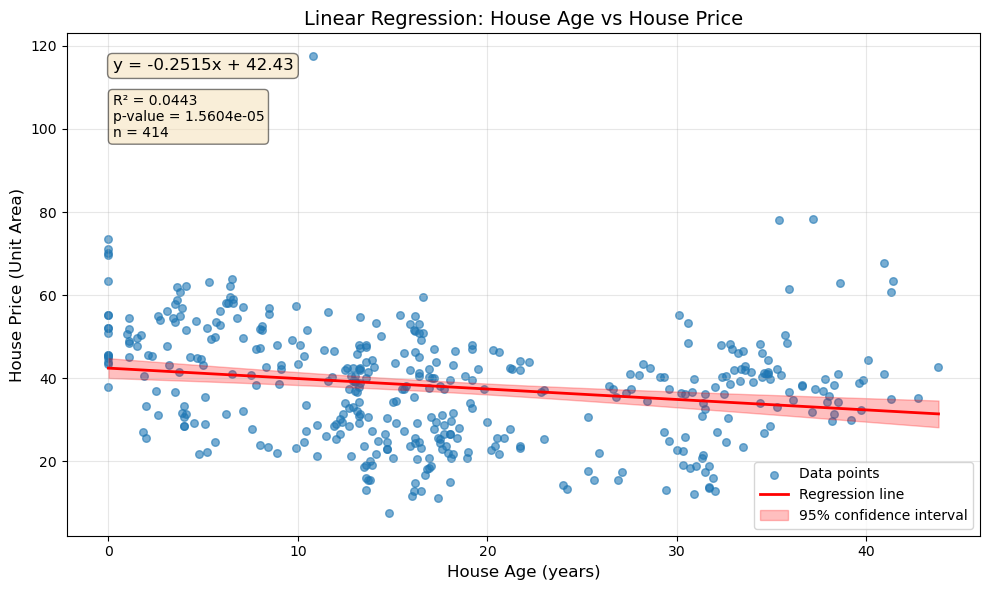


分析结果: Linear Regression: House Age vs House Price
回归方程: y = -0.2515x + 42.43
R² (决定系数): 0.044338
皮尔逊相关系数 r: -0.210567
p-value: 1.560426e-05
斜率标准误: 0.057522
样本量: 414



In [2]:
# 定义函数进行线性回归分析和绘图
def linear_regression_analysis(df, x_col, y_col, x_label, title):
    """
    进行线性回归分析并绘制散点图、回归线和置信区间
    """
    x = df[x_col].values
    y = df[y_col].values
    
    # 移除缺失值
    mask = ~(np.isnan(x) | np.isnan(y))
    x = x[mask]
    y = y[mask]
    
    # 线性回归
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    
    # 预测值
    x_pred = np.linspace(x.min(), x.max(), 100)
    y_pred = slope * x_pred + intercept
    
    # 计算置信区间
    n = len(x)
    x_mean = np.mean(x)
    residuals = y - (slope * x + intercept)
    s_err = np.sqrt(np.sum(residuals**2) / (n - 2))
    t_val = stats.t.ppf(0.975, df=n-2)
    Sxx = np.sum((x - x_mean)**2)
    
    ci = t_val * s_err * np.sqrt(1/n + (x_pred - x_mean)**2 / Sxx)
    upper = y_pred + ci
    lower = y_pred - ci
    
    # 计算统计指标
    r2 = r_value ** 2
    
    # 绘图
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # 散点图
    ax.scatter(x, y, alpha=0.6, s=30, label='Data points')
    
    # 回归线
    ax.plot(x_pred, y_pred, 'r-', linewidth=2, label='Regression line')
    
    # 置信区间
    ax.fill_between(x_pred, lower, upper, color='red', alpha=0.25, 
                    label="95% confidence interval")
    
    # 标注回归方程和统计量
    equation = f'y = {slope:.4f}x + {intercept:.2f}'
    stats_text = f'R² = {r2:.4f}\np-value = {p_value:.4e}\nn = {n}'
    
    ax.text(0.05, 0.95, equation, transform=ax.transAxes, 
            fontsize=12, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    ax.text(0.05, 0.88, stats_text, transform=ax.transAxes, 
            fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    ax.set_xlabel(x_label, fontsize=12)
    ax.set_ylabel('House Price (Unit Area)', fontsize=12)
    ax.set_title(title, fontsize=14)
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 打印详细结果
    print(f"\n{'='*60}")
    print(f"分析结果: {title}")
    print(f"{'='*60}")
    print(f"回归方程: {equation}")
    print(f"R² (决定系数): {r2:.6f}")
    print(f"皮尔逊相关系数 r: {r_value:.6f}")
    print(f"p-value: {p_value:.6e}")
    print(f"斜率标准误: {std_err:.6f}")
    print(f"样本量: {n}")
    print(f"{'='*60}\n")
    
    return {'slope': slope, 'intercept': intercept, 'r2': r2, 
            'r': r_value, 'p': p_value, 'n': n}


# 分析1: 房龄 vs 房价
print("\n" + "="*70)
print("分析一: 房龄 (House Age) 与 房价 (House Price) 的关系")
print("="*70)

result1 = linear_regression_analysis(
    df, 
    x_col='X2 house age',
    y_col='Y house price of unit area',
    x_label='House Age (years)',
    title='Linear Regression: House Age vs House Price'
)


分析二: 地铁站距离 (Distance to MRT) 与 房价 (House Price) 的关系


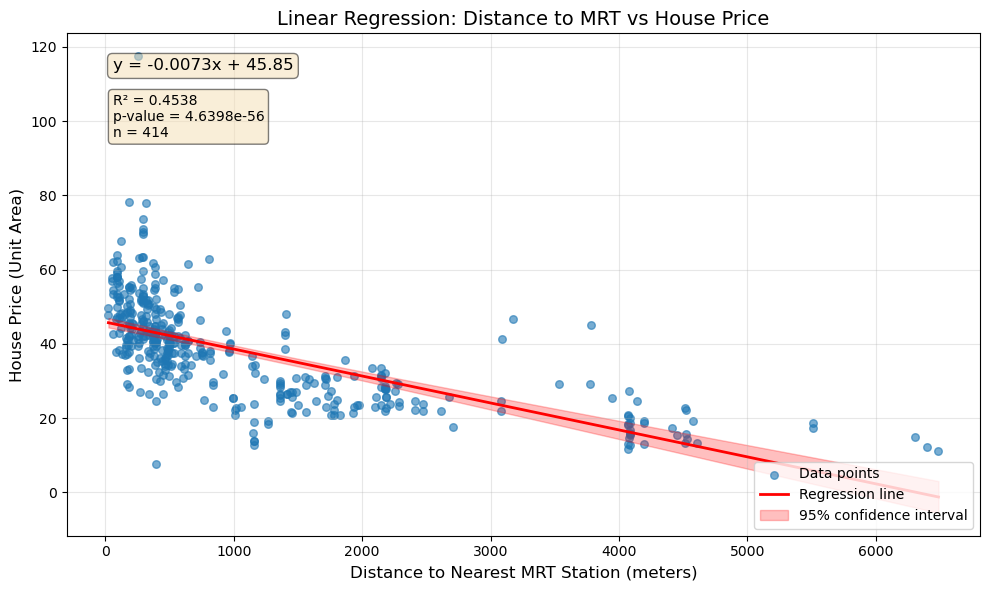


分析结果: Linear Regression: Distance to MRT vs House Price
回归方程: y = -0.0073x + 45.85
R² (决定系数): 0.453754
皮尔逊相关系数 r: -0.673613
p-value: 4.639825e-56
斜率标准误: 0.000393
样本量: 414



In [3]:
# 分析2: 地铁站距离 vs 房价
print("\n" + "="*70)
print("分析二: 地铁站距离 (Distance to MRT) 与 房价 (House Price) 的关系")
print("="*70)

result2 = linear_regression_analysis(
    df, 
    x_col='X3 distance to the nearest MRT station',
    y_col='Y house price of unit area',
    x_label='Distance to Nearest MRT Station (meters)',
    title='Linear Regression: Distance to MRT vs House Price'
)


分析三: 便利店个数 (Convenience Stores) 与 房价 (House Price) 的关系


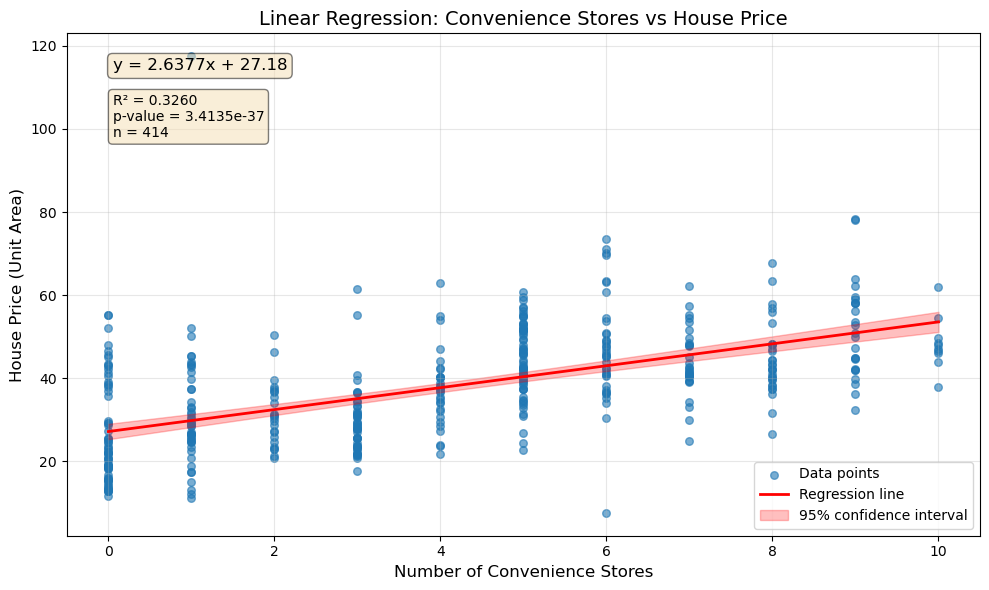


分析结果: Linear Regression: Convenience Stores vs House Price
回归方程: y = 2.6377x + 27.18
R² (决定系数): 0.326047
皮尔逊相关系数 r: 0.571005
p-value: 3.413483e-37
斜率标准误: 0.186829
样本量: 414



In [4]:
# 分析3: 便利店个数 vs 房价
print("\n" + "="*70)
print("分析三: 便利店个数 (Convenience Stores) 与 房价 (House Price) 的关系")
print("="*70)

result3 = linear_regression_analysis(
    df, 
    x_col='X4 number of convenience stores',
    y_col='Y house price of unit area',
    x_label='Number of Convenience Stores',
    title='Linear Regression: Convenience Stores vs House Price'
)

In [5]:
# 结果汇总对比
print("\n" + "="*70)
print("三个变量回归结果对比分析")
print("="*70)

results_df = pd.DataFrame({
    '自变量': ['房龄 (House Age)', '地铁站距离 (Distance to MRT)', '便利店个数 (Convenience Stores)'],
    '斜率 (Slope)': [result1['slope'], result2['slope'], result3['slope']],
    '截距 (Intercept)': [result1['intercept'], result2['intercept'], result3['intercept']],
    'R²': [result1['r2'], result2['r2'], result3['r2']],
    '相关系数 r': [result1['r'], result2['r'], result3['r']],
    'p-value': [result1['p'], result2['p'], result3['p']]
})

print(results_df.to_string(index=False))

print("\n" + "-"*70)
print("结论解读:")
print("-"*70)
print("""
1. 房龄 (House Age):
   - R² = {:.4f}，说明房龄只能解释房价约 {:.2f}% 的变异
   - p-value = {:.2e}，{} 显著
   - 斜率 = {:.4f}，表示房龄每增加1年，房价平均变化 {:.4f} 单位

2. 地铁站距离 (Distance to MRT):
   - R² = {:.4f}，说明地铁站距离能解释房价约 {:.2f}% 的变异
   - p-value = {:.2e}，{} 显著
   - 斜率 = {:.4f}，表示离地铁站距离每增加1米，房价平均变化 {:.4f} 单位

3. 便利店个数 (Convenience Stores):
   - R² = {:.4f}，说明便利店个数能解释房价约 {:.2f}% 的变异
   - p-value = {:.2e}，{} 显著
   - 斜率 = {:.4f}，表示便利店每增加1个，房价平均变化 {:.4f} 单位
""".format(
    result1['r2'], result1['r2']*100, result1['p'], 
    "显著" if result1['p'] < 0.05 else "不显著",
    result1['slope'], result1['slope'],
    
    result2['r2'], result2['r2']*100, result2['p'],
    "显著" if result2['p'] < 0.05 else "不显著",
    result2['slope'], result2['slope'],
    
    result3['r2'], result3['r2']*100, result3['p'],
    "显著" if result3['p'] < 0.05 else "不显著",
    result3['slope'], result3['slope']
))


三个变量回归结果对比分析
                       自变量  斜率 (Slope)  截距 (Intercept)       R²    相关系数 r      p-value
            房龄 (House Age)   -0.251488       42.434697 0.044338 -0.210567 1.560426e-05
   地铁站距离 (Distance to MRT)   -0.007262       45.851427 0.453754 -0.673613 4.639825e-56
便利店个数 (Convenience Stores)    2.637653       27.181105 0.326047  0.571005 3.413483e-37

----------------------------------------------------------------------
结论解读:
----------------------------------------------------------------------

1. 房龄 (House Age):
   - R² = 0.0443，说明房龄只能解释房价约 4.43% 的变异
   - p-value = 1.56e-05，显著 显著
   - 斜率 = -0.2515，表示房龄每增加1年，房价平均变化 -0.2515 单位

2. 地铁站距离 (Distance to MRT):
   - R² = 0.4538，说明地铁站距离能解释房价约 45.38% 的变异
   - p-value = 4.64e-56，显著 显著
   - 斜率 = -0.0073，表示离地铁站距离每增加1米，房价平均变化 -0.0073 单位

3. 便利店个数 (Convenience Stores):
   - R² = 0.3260，说明便利店个数能解释房价约 32.60% 的变异
   - p-value = 3.41e-37，显著 显著
   - 斜率 = 2.6377，表示便利店每增加1个，房价平均变化 2.6377 单位



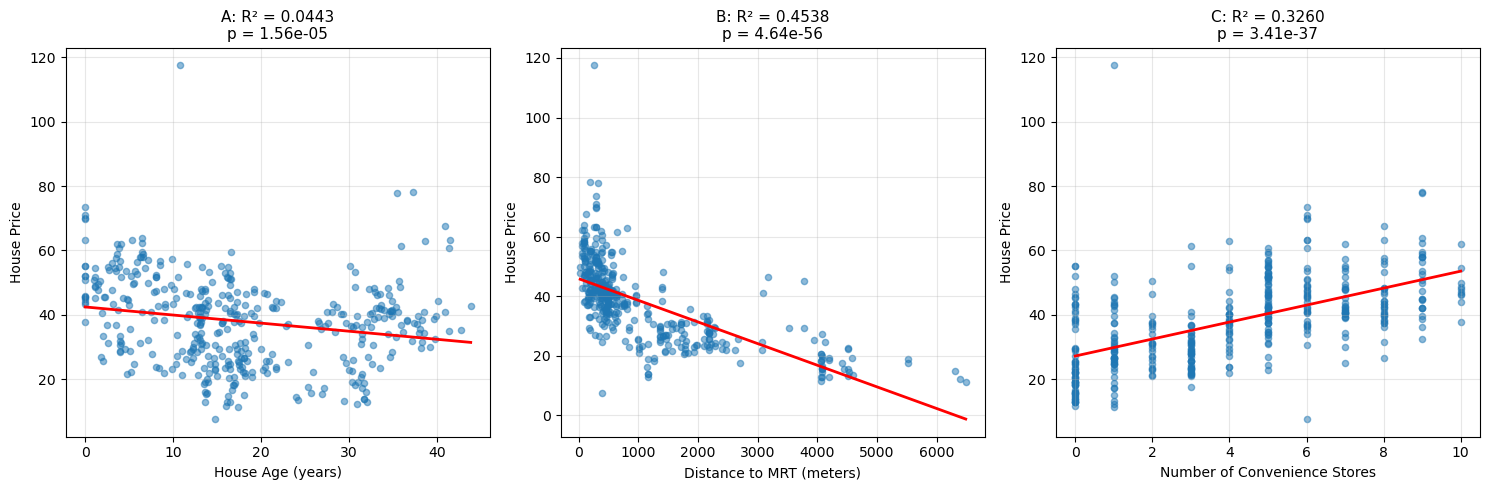


综合分析结论

从三个变量的回归分析可以看出：

1. 地铁站距离 (R² = 0.4538) 是三个变量中对房价解释力最强的因素，
   表明交通便利性对房价有重要影响。负斜率表明离地铁站越远，房价越低。

2. 便利店个数 (R² = 0.3260) 的解释力次之，正斜率表明配套设施越完善，
   房价越高。但R²相对较小，说明还有其他重要因素影响房价。

3. 房龄 (R² = 0.0443) 对房价的解释力最弱，说明在这个数据集中，
   房屋年龄不是决定房价的主要因素。

4. 三个变量的p值都小于0.05，统计上显著，但与房价的关系强度不同。



In [6]:
# 创建组合图对比三个变量的拟合效果
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

vars_info = [
    ('X2 house age', 'House Age (years)', result1),
    ('X3 distance to the nearest MRT station', 'Distance to MRT (meters)', result2),
    ('X4 number of convenience stores', 'Number of Convenience Stores', result3)
]

for idx, (x_col, x_label, result) in enumerate(vars_info):
    x = df[x_col].values
    y = df['Y house price of unit area'].values
    
    # 移除缺失值
    mask = ~(np.isnan(x) | np.isnan(y))
    x = x[mask]
    y = y[mask]
    
    # 散点图
    axes[idx].scatter(x, y, alpha=0.5, s=20)
    
    # 回归线
    x_pred = np.linspace(x.min(), x.max(), 100)
    y_pred = result['slope'] * x_pred + result['intercept']
    axes[idx].plot(x_pred, y_pred, 'r-', linewidth=2)
    
    # 标注
    axes[idx].set_xlabel(x_label, fontsize=10)
    axes[idx].set_ylabel('House Price', fontsize=10)
    axes[idx].set_title(f'{chr(65+idx)}: R² = {result["r2"]:.4f}\np = {result["p"]:.2e}', fontsize=11)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("综合分析结论")
print("="*70)
print("""
从三个变量的回归分析可以看出：

1. 地铁站距离 (R² = {:.4f}) 是三个变量中对房价解释力最强的因素，
   表明交通便利性对房价有重要影响。负斜率表明离地铁站越远，房价越低。

2. 便利店个数 (R² = {:.4f}) 的解释力次之，正斜率表明配套设施越完善，
   房价越高。但R²相对较小，说明还有其他重要因素影响房价。

3. 房龄 (R² = {:.4f}) 对房价的解释力最弱，说明在这个数据集中，
   房屋年龄不是决定房价的主要因素。

4. 三个变量的p值都小于0.05，统计上显著，但与房价的关系强度不同。
""".format(result2['r2'], result3['r2'], result1['r2']))

C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 22238 (\N{CJK UNIFIED IDEOGRAPH-56DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 24402 (\N{CJK UNIFIED IDEOGRAPH-5F52}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 26041 (\N{CJK UNIFIED IDEOGRAPH-65B9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 31243 (\N{CJK UNIFIED IDEOGRAPH-7A0B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\23983\AppData\Roaming\mamba\envs\pygeo\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22238 (\N{CJK UNIFIED IDEOGRAPH-56DE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\23983\AppData\Roaming\mamba\envs\py

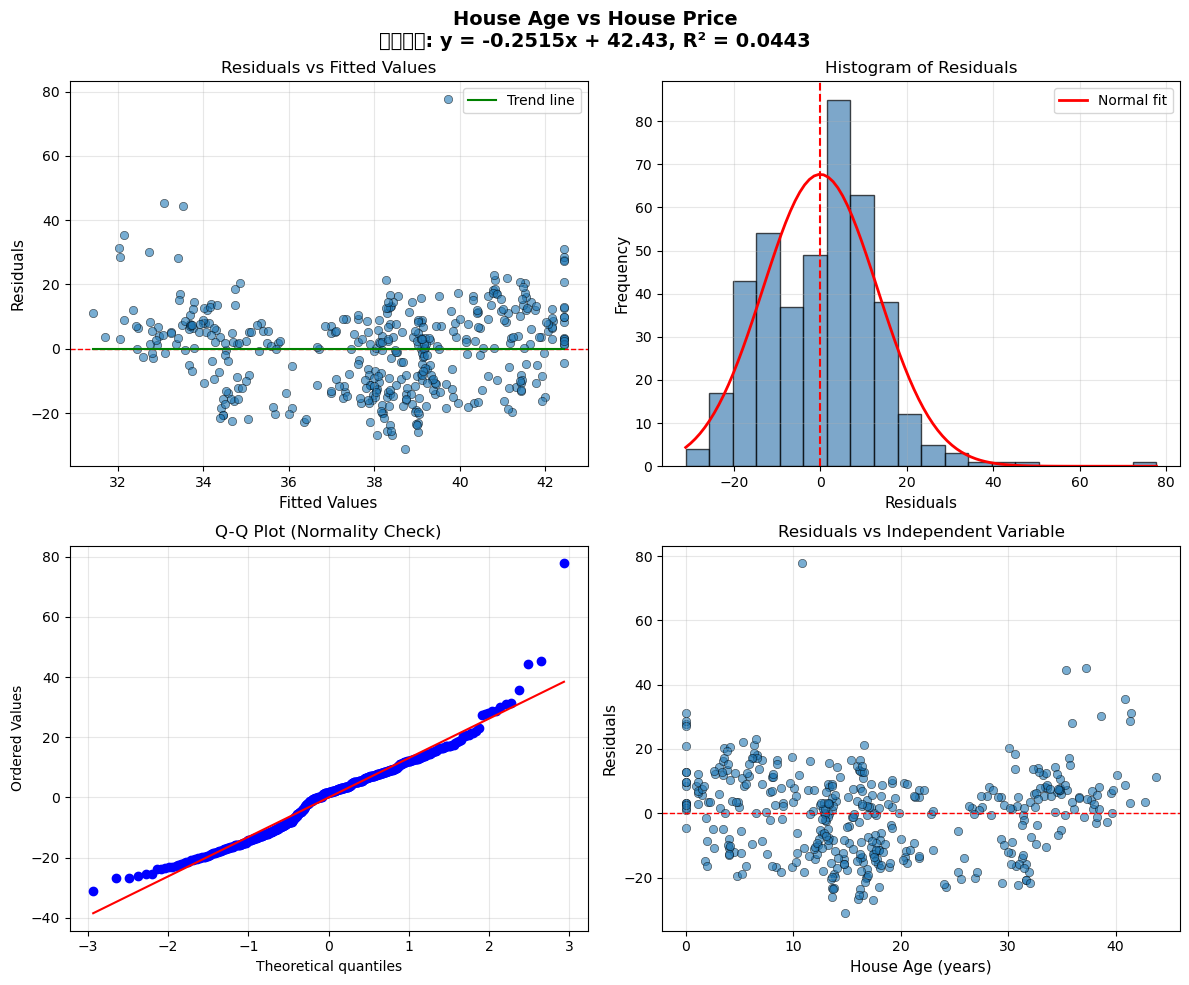


残差分析 - House Age vs House Price
残差均值: 0.000000
残差标准差: 13.285348
残差偏度: 0.588902
残差峰度: 2.348293
Shapiro-Wilk正态性检验 p-value: 1.267190e-08



In [8]:
#为三个线性回归模型分别绘制残差散点图和直方图，以检查模型的假设是否满足
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# 读取数据
df = pd.read_csv('./data/linear_regression/Real estate.csv')

# 定义线性回归和残差分析函数
def residual_analysis(df, x_col, y_col, x_label, title):
    """
    进行线性回归并绘制残差图
    """
    x = df[x_col].values
    y = df[y_col].values
    
    # 移除缺失值
    mask = ~(np.isnan(x) | np.isnan(y))
    x = x[mask]
    y = y[mask]
    
    # 线性回归
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    
    # 预测值和残差
    y_pred = slope * x + intercept
    residuals = y - y_pred
    
    # 标准化残差
    residuals_std = residuals / np.std(residuals)
    
    # 计算统计量
    r2 = r_value ** 2
    
    # 创建图形
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    fig.suptitle(f'{title}\n回归方程: y = {slope:.4f}x + {intercept:.2f}, R² = {r2:.4f}', 
                 fontsize=14, fontweight='bold')
    
    # 1. 残差 vs 拟合值散点图
    axes[0, 0].scatter(y_pred, residuals, alpha=0.6, edgecolors='k', linewidth=0.5)
    axes[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=1)
    axes[0, 0].set_xlabel('Fitted Values', fontsize=11)
    axes[0, 0].set_ylabel('Residuals', fontsize=11)
    axes[0, 0].set_title('Residuals vs Fitted Values', fontsize=12)
    axes[0, 0].grid(True, alpha=0.3)
    
    # 添加趋势线
    z = np.polyfit(y_pred, residuals, 1)
    p = np.poly1d(z)
    axes[0, 0].plot(sorted(y_pred), p(sorted(y_pred)), 'green', linewidth=1.5, 
                    label='Trend line')
    axes[0, 0].legend()
    
    # 2. 残差直方图
    axes[0, 1].hist(residuals, bins=20, edgecolor='black', alpha=0.7, color='steelblue')
    axes[0, 1].axvline(x=0, color='red', linestyle='--', linewidth=1.5)
    axes[0, 1].set_xlabel('Residuals', fontsize=11)
    axes[0, 1].set_ylabel('Frequency', fontsize=11)
    axes[0, 1].set_title('Histogram of Residuals', fontsize=12)
    axes[0, 1].grid(True, alpha=0.3)
    
    # 添加正态分布拟合曲线
    mu, std = np.mean(residuals), np.std(residuals)
    x_hist = np.linspace(residuals.min(), residuals.max(), 100)
    y_hist = stats.norm.pdf(x_hist, mu, std) * len(residuals) * (residuals.max() - residuals.min()) / 20
    axes[0, 1].plot(x_hist, y_hist, 'r-', linewidth=2, label='Normal fit')
    axes[0, 1].legend()
    
    # 3. Q-Q图（正态概率图）
    stats.probplot(residuals, dist="norm", plot=axes[1, 0])
    axes[1, 0].set_title('Q-Q Plot (Normality Check)', fontsize=12)
    axes[1, 0].grid(True, alpha=0.3)
    
    # 4. 残差 vs 自变量
    axes[1, 1].scatter(x, residuals, alpha=0.6, edgecolors='k', linewidth=0.5)
    axes[1, 1].axhline(y=0, color='red', linestyle='--', linewidth=1)
    axes[1, 1].set_xlabel(x_label, fontsize=11)
    axes[1, 1].set_ylabel('Residuals', fontsize=11)
    axes[1, 1].set_title('Residuals vs Independent Variable', fontsize=12)
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 打印残差统计信息
    print(f"\n{'='*60}")
    print(f"残差分析 - {title}")
    print(f"{'='*60}")
    print(f"残差均值: {np.mean(residuals):.6f}")
    print(f"残差标准差: {np.std(residuals):.6f}")
    print(f"残差偏度: {stats.skew(residuals):.6f}")
    print(f"残差峰度: {stats.kurtosis(residuals):.6f}")
    print(f"Shapiro-Wilk正态性检验 p-value: {stats.shapiro(residuals)[1]:.6e}")
    print(f"{'='*60}\n")
    
    return residuals


# 分析1: 房龄 vs 房价
residuals1 = residual_analysis(
    df, 
    x_col='X2 house age',
    y_col='Y house price of unit area',
    x_label='House Age (years)',
    title='House Age vs House Price'
)

C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 22238 (\N{CJK UNIFIED IDEOGRAPH-56DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 24402 (\N{CJK UNIFIED IDEOGRAPH-5F52}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 26041 (\N{CJK UNIFIED IDEOGRAPH-65B9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 31243 (\N{CJK UNIFIED IDEOGRAPH-7A0B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


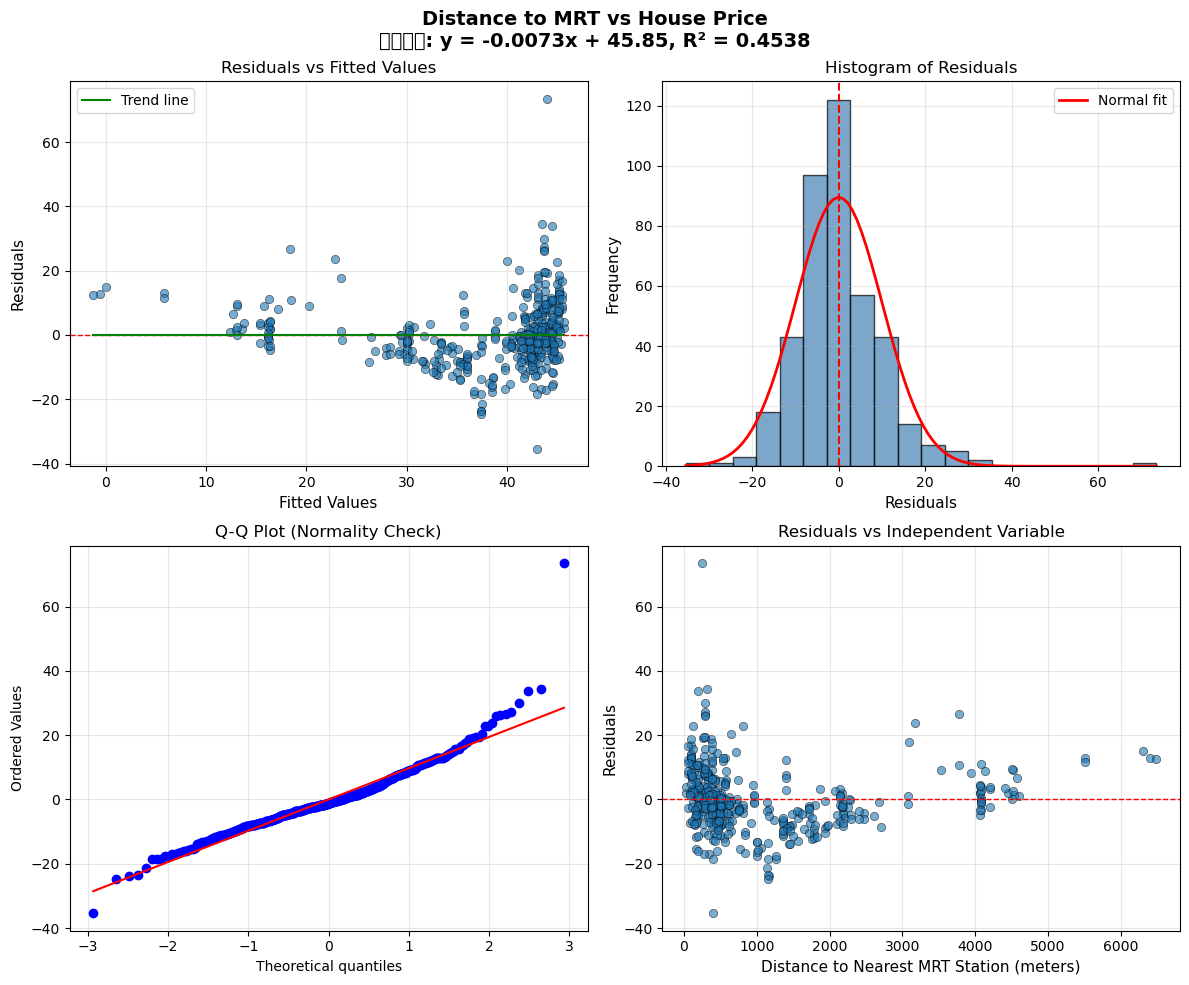


残差分析 - Distance to MRT vs House Price
残差均值: -0.000000
残差标准差: 10.044190
残差偏度: 1.262585
残差峰度: 7.135496
Shapiro-Wilk正态性检验 p-value: 9.640126e-13



In [9]:
# 分析2: 地铁站距离 vs 房价
residuals2 = residual_analysis(
    df, 
    x_col='X3 distance to the nearest MRT station',
    y_col='Y house price of unit area',
    x_label='Distance to Nearest MRT Station (meters)',
    title='Distance to MRT vs House Price'
)

C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 22238 (\N{CJK UNIFIED IDEOGRAPH-56DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 24402 (\N{CJK UNIFIED IDEOGRAPH-5F52}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 26041 (\N{CJK UNIFIED IDEOGRAPH-65B9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1196368472.py:84: UserWarning: Glyph 31243 (\N{CJK UNIFIED IDEOGRAPH-7A0B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


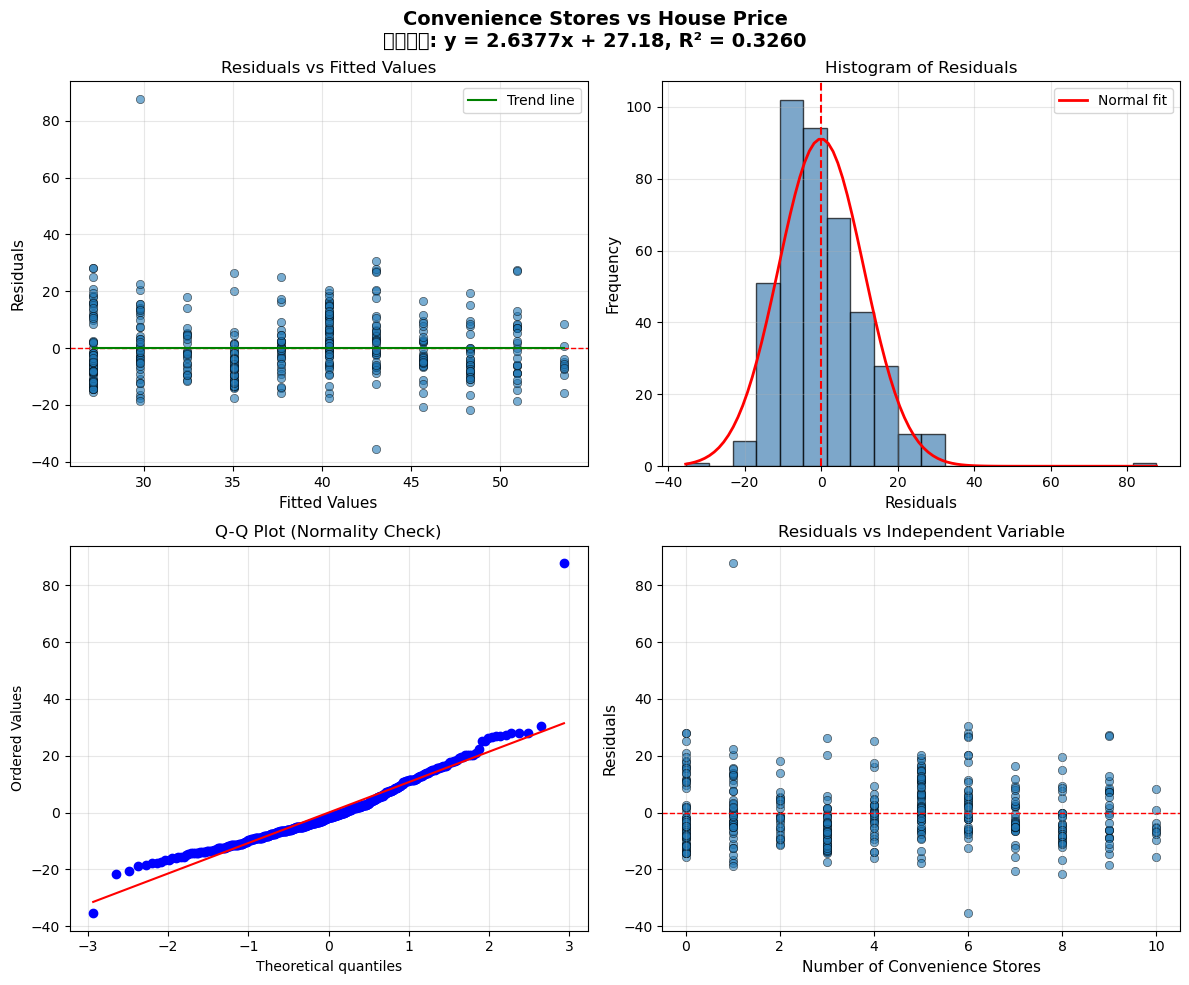


残差分析 - Convenience Stores vs House Price
残差均值: 0.000000
残差标准差: 11.156702
残差偏度: 1.552670
残差峰度: 8.515621
Shapiro-Wilk正态性检验 p-value: 2.290856e-14



In [10]:
# 分析3: 便利店个数 vs 房价
residuals3 = residual_analysis(
    df, 
    x_col='X4 number of convenience stores',
    y_col='Y house price of unit area',
    x_label='Number of Convenience Stores',
    title='Convenience Stores vs House Price'
)


三维模型残差分析综合对比


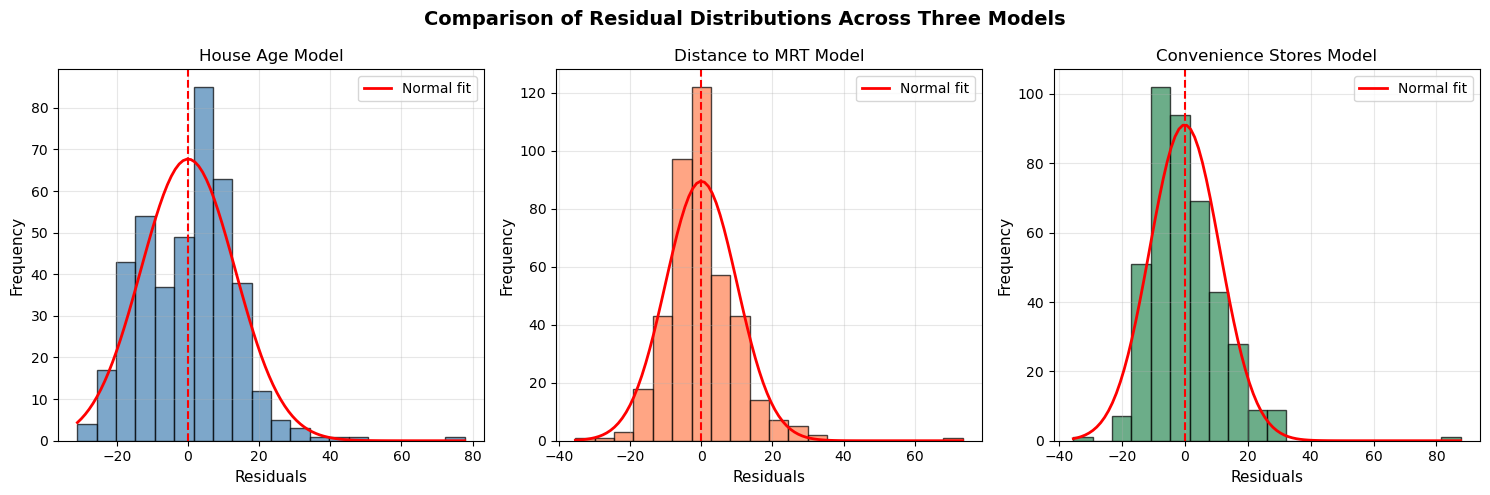

In [11]:
# 综合残差对比分析
print("\n" + "="*70)
print("三维模型残差分析综合对比")
print("="*70)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

residuals_list = [residuals1, residuals2, residuals3]
titles = ['House Age Model', 'Distance to MRT Model', 'Convenience Stores Model']
colors = ['steelblue', 'coral', 'seagreen']

for i, (res, title, color) in enumerate(zip(residuals_list, titles, colors)):
    axes[i].hist(res, bins=20, edgecolor='black', alpha=0.7, color=color)
    axes[i].axvline(x=0, color='red', linestyle='--', linewidth=1.5)
    axes[i].set_xlabel('Residuals', fontsize=11)
    axes[i].set_ylabel('Frequency', fontsize=11)
    axes[i].set_title(title, fontsize=12)
    axes[i].grid(True, alpha=0.3)
    
    # 添加正态分布拟合
    mu, std = np.mean(res), np.std(res)
    x_hist = np.linspace(res.min(), res.max(), 100)
    y_hist = stats.norm.pdf(x_hist, mu, std) * len(res) * (res.max() - res.min()) / 20
    axes[i].plot(x_hist, y_hist, 'r-', linewidth=2, label='Normal fit')
    axes[i].legend()

plt.suptitle('Comparison of Residual Distributions Across Three Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### 2.三江源地区2001-2020年NPP、气温和降水的变化趋势

In [16]:
#三江源地区2001-2020年NPP、气温和降水的变化趋势
import os
import numpy as np
import rasterio
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from rasterio.mask import mask
import geopandas as gpd
from shapely.geometry import Polygon, box

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 数据路径
base_path = './data/SanJiangYuan'
npp_path = os.path.join(base_path, 'NPP')
temp_path = os.path.join(base_path, 'Temperature')
precip_path = os.path.join(base_path, 'Precipitation')

# 读取三江源边界（如果有的话，否则使用所有数据的边界）
# 这里我们使用所有数据的平均边界

# 获取年份列表
years = list(range(2001, 2021))
print(f"年份: {years}")

年份: [2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020]


In [17]:
def calculate_mean_value(data_path, year, pattern):
    """
    计算单年栅格数据的均值
    """
    if pattern == 'npp':
        filename = f"NPP_{year}.tif"
    elif pattern == 'temp':
        filename = f"tmp_{year}.tif"
    elif pattern == 'precip':
        filename = f"pre_{year}.tif"
    else:
        raise ValueError(f"Unknown pattern: {pattern}")
    
    filepath = os.path.join(data_path, filename)
    
    if not os.path.exists(filepath):
        print(f"文件不存在: {filepath}")
        return np.nan
    
    with rasterio.open(filepath) as src:
        data = src.read(1)
        # 只计算有效值（非NaN、非NoData）
        valid_data = data[(data != src.nodata) & (~np.isnan(data))]
        if len(valid_data) == 0:
            return np.nan
        return np.mean(valid_data)

# 计算各年数据均值
npp_values = []
temp_values = []
precip_values = []

print("正在计算各年数据均值...")

for year in years:
    # NPP
    npp_mean = calculate_mean_value(npp_path, year, 'npp')
    npp_values.append(npp_mean)
    
    # 气温
    temp_mean = calculate_mean_value(temp_path, year, 'temp')
    temp_values.append(temp_mean)
    
    # 降水
    precip_mean = calculate_mean_value(precip_path, year, 'precip')
    precip_values.append(precip_mean)
    
    print(f"{year}: NPP={npp_mean:.2f}, 气温={temp_mean:.2f}℃, 降水={precip_mean:.1f}mm")

正在计算各年数据均值...
2001: NPP=0.13, 气温=1.83℃, 降水=402.5mm
2002: NPP=0.14, 气温=1.93℃, 降水=413.0mm
2003: NPP=0.13, 气温=2.06℃, 降水=438.6mm
2004: NPP=0.13, 气温=1.83℃, 降水=446.4mm
2005: NPP=0.14, 气温=2.10℃, 降水=484.5mm
2006: NPP=0.16, 气温=2.42℃, 降水=384.3mm
2007: NPP=0.14, 气温=2.54℃, 降水=446.1mm
2008: NPP=0.13, 气温=1.87℃, 降水=460.9mm
2009: NPP=0.15, 气温=2.66℃, 降水=512.3mm
2010: NPP=0.16, 气温=2.79℃, 降水=470.3mm
2011: NPP=0.14, 气温=2.20℃, 降水=469.0mm
2012: NPP=0.15, 气温=2.07℃, 降水=498.6mm
2013: NPP=0.15, 气温=2.36℃, 降水=412.5mm
2014: NPP=0.13, 气温=2.00℃, 降水=497.8mm
2015: NPP=0.14, 气温=1.93℃, 降水=386.9mm
2016: NPP=0.15, 气温=2.58℃, 降水=411.1mm
2017: NPP=0.15, 气温=2.47℃, 降水=494.7mm
2018: NPP=0.16, 气温=2.33℃, 降水=497.8mm
2019: NPP=0.16, 气温=2.27℃, 降水=481.1mm
2020: NPP=0.16, 气温=2.26℃, 降水=450.6mm



有效数据点: 20
   Year       NPP  Temperature  Precipitation
0  2001  0.128544     1.825920     402.451447
1  2002  0.139618     1.931232     412.967865
2  2003  0.127629     2.060271     438.551086
3  2004  0.127591     1.834034     446.356750
4  2005  0.141526     2.103474     484.522552

有效数据点: 20
   Year       NPP  Temperature  Precipitation
0  2001  0.128544     1.825920     402.451447
1  2002  0.139618     1.931232     412.967865
2  2003  0.127629     2.060271     438.551086
3  2004  0.127591     1.834034     446.356750
4  2005  0.141526     2.103474     484.522552
三江源地区NPP、气温、降水变化趋势分析 (2001-2020)


C:\Users\23983\AppData\Local\Temp\ipykernel_15392\3038208255.py:89: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.tight_layout()
c:\Users\23983\AppData\Roaming\mamba\envs\pygeo\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


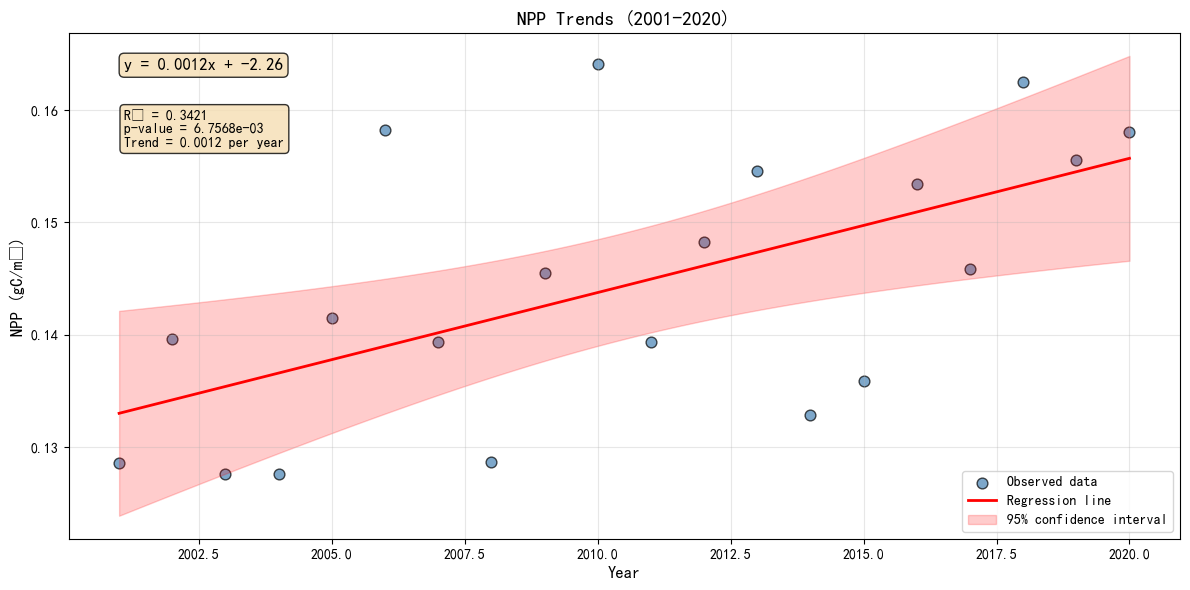


NPP 趋势分析
回归方程: y = 0.0012x + -2.26
每年变化量: 0.0012 NPP
R² (决定系数): 0.342061
皮尔逊相关系数 r: 0.584860
p-value: 6.756755e-03
斜率标准误: 0.000391
样本量: 20
趋势结论: 上升趋势，显著



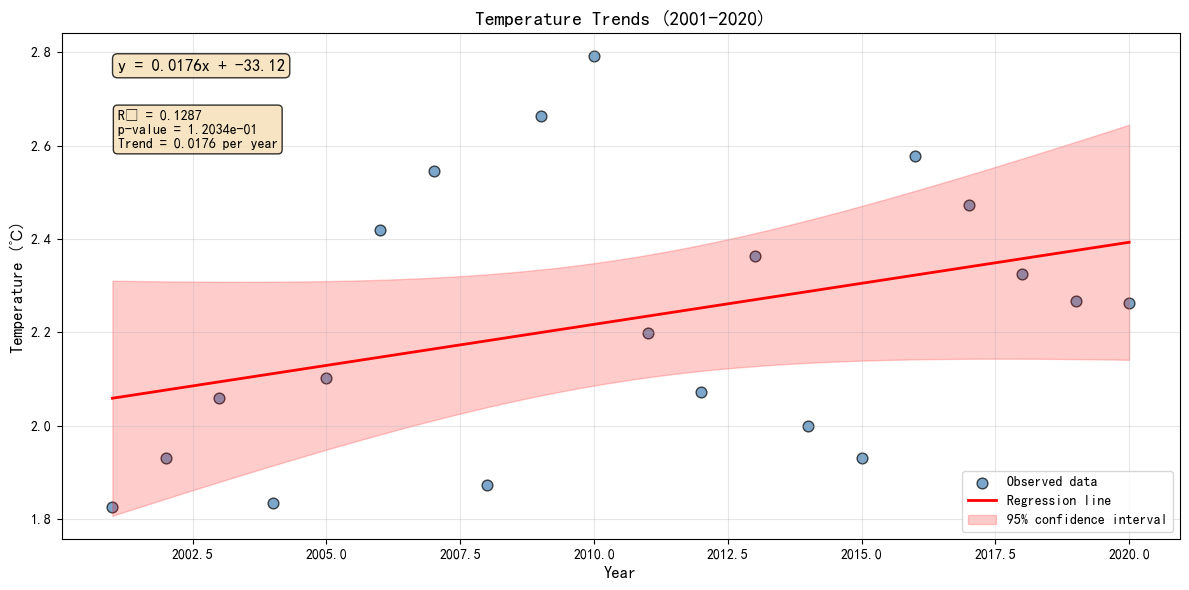


Temperature 趋势分析
回归方程: y = 0.0176x + -33.12
每年变化量: 0.0176 Temperature
R² (决定系数): 0.128706
皮尔逊相关系数 r: 0.358757
p-value: 1.203425e-01
斜率标准误: 0.010780
样本量: 20
趋势结论: 无明显趋势，不显著



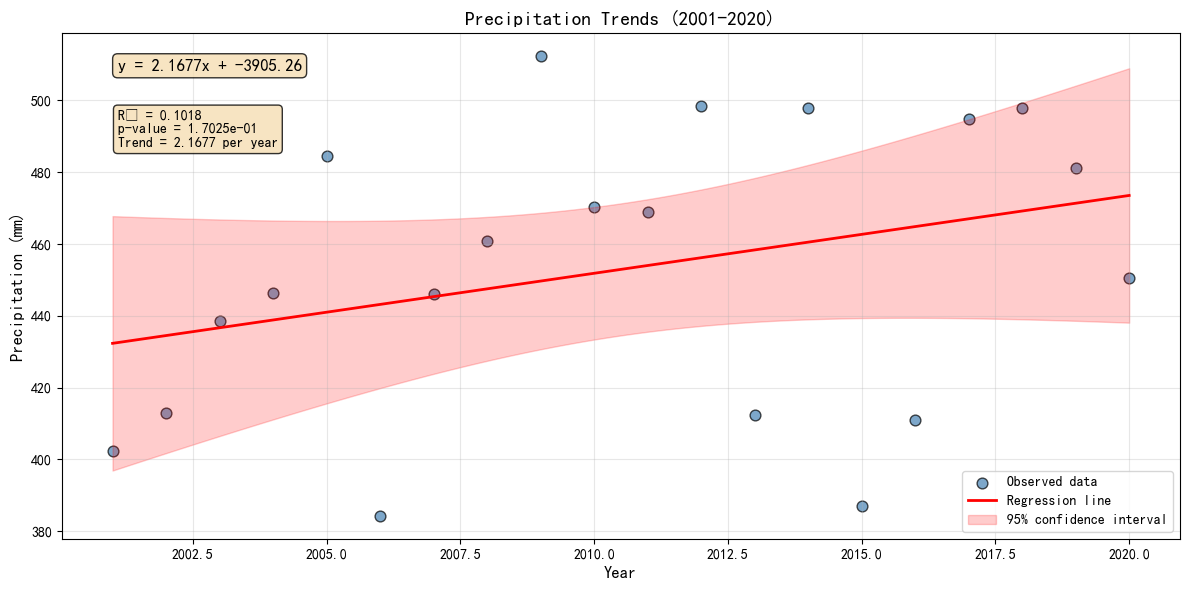


Precipitation 趋势分析
回归方程: y = 2.1677x + -3905.26
每年变化量: 2.1677 Precipitation
R² (决定系数): 0.101832
皮尔逊相关系数 r: 0.319112
p-value: 1.702521e-01
斜率标准误: 1.517409
样本量: 20
趋势结论: 无明显趋势，不显著



In [18]:
# 创建数据框
df = pd.DataFrame({
    'Year': years,
    'NPP': npp_values,
    'Temperature': temp_values,
    'Precipitation': precip_values
})

# 移除缺失值
df_clean = df.dropna()
print(f"\n有效数据点: {len(df_clean)}")
print(df_clean.head())

# 创建数据框
df = pd.DataFrame({
    'Year': years,
    'NPP': npp_values,
    'Temperature': temp_values,
    'Precipitation': precip_values
})

# 移除缺失值
df_clean = df.dropna()
print(f"\n有效数据点: {len(df_clean)}")
print(df_clean.head())

# 定义线性回归分析函数
def trend_analysis(df, var_name, y_label, title_prefix):
    """
    对时间序列进行线性回归分析
    """
    x = df['Year'].values
    y = df[var_name].values
    
    # 线性回归
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    
    # 预测值
    y_pred = slope * x + intercept
    
    # 计算置信区间
    n = len(x)
    x_mean = np.mean(x)
    residuals = y - y_pred
    s_err = np.sqrt(np.sum(residuals**2) / (n - 2))
    t_val = stats.t.ppf(0.975, df=n-2)
    Sxx = np.sum((x - x_mean)**2)
    
    ci = t_val * s_err * np.sqrt(1/n + (x - x_mean)**2 / Sxx)
    upper = y_pred + ci
    lower = y_pred - ci
    
    # 计算统计量
    r2 = r_value ** 2
    
    # 绘图
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # 散点图
    ax.scatter(x, y, s=60, alpha=0.7, color='steelblue', edgecolors='k', label='Observed data')
    
    # 回归线
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept
    ax.plot(x_line, y_line, 'r-', linewidth=2, label='Regression line')
    
    # 置信区间
    ci_line = t_val * s_err * np.sqrt(1/n + (x_line - x_mean)**2 / Sxx)
    ax.fill_between(x_line, y_line - ci_line, y_line + ci_line, 
                    color='red', alpha=0.2, label="95% confidence interval")
    
    # 标注
    equation = f'y = {slope:.4f}x + {intercept:.2f}'
    stats_text = f'R² = {r2:.4f}\np-value = {p_value:.4e}\nTrend = {slope:.4f} per year'
    
    ax.text(0.05, 0.95, equation, transform=ax.transAxes, 
            fontsize=12, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    ax.text(0.05, 0.85, stats_text, transform=ax.transAxes, 
            fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    ax.set_xlabel('Year', fontsize=12)
    ax.set_ylabel(y_label, fontsize=12)
    ax.set_title(f'{title_prefix} Trends (2001-2020)', fontsize=14, fontweight='bold')
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 打印详细结果
    print(f"\n{'='*60}")
    print(f"{title_prefix} 趋势分析")
    print(f"{'='*60}")
    print(f"回归方程: {equation}")
    print(f"每年变化量: {slope:.4f} {y_label.split()[0]}")
    print(f"R² (决定系数): {r2:.6f}")
    print(f"皮尔逊相关系数 r: {r_value:.6f}")
    print(f"p-value: {p_value:.6e}")
    print(f"斜率标准误: {std_err:.6f}")
    print(f"样本量: {n}")
    
    # 趋势解读
    if p_value < 0.05:
        significance = "显著"
        if slope > 0:
            trend_dir = "上升"
        else:
            trend_dir = "下降"
    else:
        significance = "不显著"
        trend_dir = "无明显"
    
    print(f"趋势结论: {trend_dir}趋势，{significance}")
    print(f"{'='*60}\n")
    
    return {'slope': slope, 'intercept': intercept, 'r2': r2, 
            'r': r_value, 'p': p_value, 'n': n}


print("=" * 70)
print("三江源地区NPP、气温、降水变化趋势分析 (2001-2020)")
print("=" * 70)

# 分析NPP趋势
result_npp = trend_analysis(
    df_clean, 'NPP', 'NPP (gC/m²)', 'NPP'
)

# 分析气温趋势
result_temp = trend_analysis(
    df_clean, 'Temperature', 'Temperature (℃)', 'Temperature'
)

# 分析降水趋势
result_precip = trend_analysis(
    df_clean, 'Precipitation', 'Precipitation (mm)', 'Precipitation'
)

C:\Users\23983\AppData\Local\Temp\ipykernel_15392\3994426906.py:51: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.tight_layout()


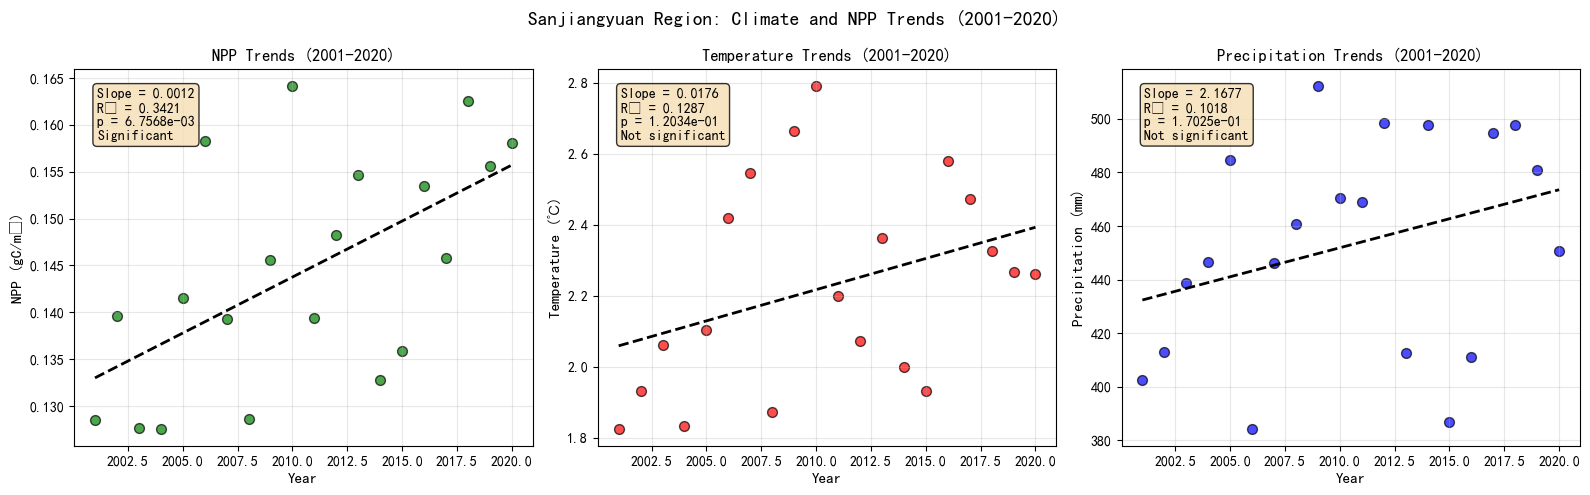

In [19]:
# 三变量趋势对比图
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

variables = [('NPP', 'NPP (gC/m²)', npp_values, result_npp),
             ('Temperature', 'Temperature (℃)', temp_values, result_temp),
             ('Precipitation', 'Precipitation (mm)', precip_values, result_precip)]

colors = ['green', 'red', 'blue']

for idx, (var_name, ylabel, values, result) in enumerate(variables):
    ax = axes[idx]
    x = years
    y = values
    
    # 移除缺失值
    mask = ~np.isnan(y)
    x_clean = np.array(x)[mask]
    y_clean = np.array(y)[mask]
    
    # 回归线
    slope = result['slope']
    intercept = result['intercept']
    r2 = result['r2']
    p = result['p']
    
    # 散点图
    ax.scatter(x_clean, y_clean, s=50, alpha=0.7, color=colors[idx], edgecolors='k')
    
    # 回归线
    x_line = np.linspace(x_clean.min(), x_clean.max(), 100)
    y_line = slope * x_line + intercept
    ax.plot(x_line, y_line, 'k--', linewidth=2)
    
    # 标注
    trend_text = f'Slope = {slope:.4f}\nR² = {r2:.4f}\np = {p:.4e}'
    if p < 0.05:
        trend_text += '\nSignificant'
    else:
        trend_text += '\nNot significant'
    
    ax.text(0.05, 0.95, trend_text, transform=ax.transAxes, 
            fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    ax.set_xlabel('Year', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(f'{var_name} Trends (2001-2020)', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.suptitle('Sanjiangyuan Region: Climate and NPP Trends (2001-2020)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [20]:
# 数据汇总表
print("\n" + "=" * 80)
print("三江源地区2001-2020年NPP、气温、降水数据统计汇总")
print("=" * 80)

summary_df = pd.DataFrame({
    '变量': ['NPP (gC/m²)', '气温 (℃)', '降水 (mm)'],
    '均值': [np.mean([v for v in npp_values if not np.isnan(v)]),
             np.mean([v for v in temp_values if not np.isnan(v)]),
             np.mean([v for v in precip_values if not np.isnan(v)])],
    '标准差': [np.std([v for v in npp_values if not np.isnan(v)]),
              np.std([v for v in temp_values if not np.isnan(v)]),
              np.std([v for v in precip_values if not np.isnan(v)])],
    '年变化率': [result_npp['slope'], result_temp['slope'], result_precip['slope']],
    'R²': [result_npp['r2'], result_temp['r2'], result_precip['r2']],
    'p-value': [result_npp['p'], result_temp['p'], result_precip['p']],
    '趋势显著性': ['显著' if result_npp['p'] < 0.05 else '不显著',
                 '显著' if result_temp['p'] < 0.05 else '不显著',
                 '显著' if result_precip['p'] < 0.05 else '不显著']
})

print(summary_df.to_string(index=False))


三江源地区2001-2020年NPP、气温、降水数据统计汇总
         变量         均值       标准差     年变化率       R²  p-value 趋势显著性
NPP (gC/m²)   0.144355  0.011782 0.001195 0.342061 0.006757    显著
     气温 (℃)   2.226133  0.282540 0.017579 0.128706 0.120342   不显著
    降水 (mm) 452.942230 39.170216 2.167720 0.101832 0.170252   不显著


In [1]:
#分析 NPP（因变量）和气温、降水（自变量）间的相关系数和线性关系
import os
import numpy as np
import rasterio
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 数据路径
base_path = './data/SanJiangYuan'
npp_path = os.path.join(base_path, 'NPP')
temp_path = os.path.join(base_path, 'Temperature')
precip_path = os.path.join(base_path, 'Precipitation')

# 获取年份列表
years = list(range(2001, 2021))
print(f"年份: {years}")

# 读取数据函数
def read_raster_mean(data_path, year, var_type):
    """
    读取栅格数据并计算均值
    var_type: 'npp', 'temp', 'precip'
    """
    if var_type == 'npp':
        filename = f"NPP_{year}.tif"
    elif var_type == 'temp':
        filename = f"tmp_{year}.tif"
    elif var_type == 'precip':
        filename = f"pre_{year}.tif"
    else:
        return np.nan
    
    filepath = os.path.join(data_path, filename)
    
    if not os.path.exists(filepath):
        print(f"文件不存在: {filepath}")
        return np.nan
    
    with rasterio.open(filepath) as src:
        data = src.read(1)
        # 只计算有效值
        valid_data = data[(data != src.nodata) & (~np.isnan(data))]
        if len(valid_data) == 0:
            return np.nan
        return np.mean(valid_data)

# 读取各年数据
npp_vals = []
temp_vals = []
precip_vals = []

print("正在读取数据...")
for year in years:
    npp = read_raster_mean(npp_path, year, 'npp')
    temp = read_raster_mean(temp_path, year, 'temp')
    precip = read_raster_mean(precip_path, year, 'precip')
    
    npp_vals.append(npp)
    temp_vals.append(temp)
    precip_vals.append(precip)
    

# 创建数据框，移除缺失值
df = pd.DataFrame({
    'Year': years,
    'NPP': npp_vals,
    'Temperature': temp_vals,
    'Precipitation': precip_vals
}).dropna()


年份: [2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020]
正在读取数据...


三江源地区NPP与气候因子相关性分析


C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1477038979.py:64: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.tight_layout()
c:\Users\23983\AppData\Roaming\mamba\envs\pygeo\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


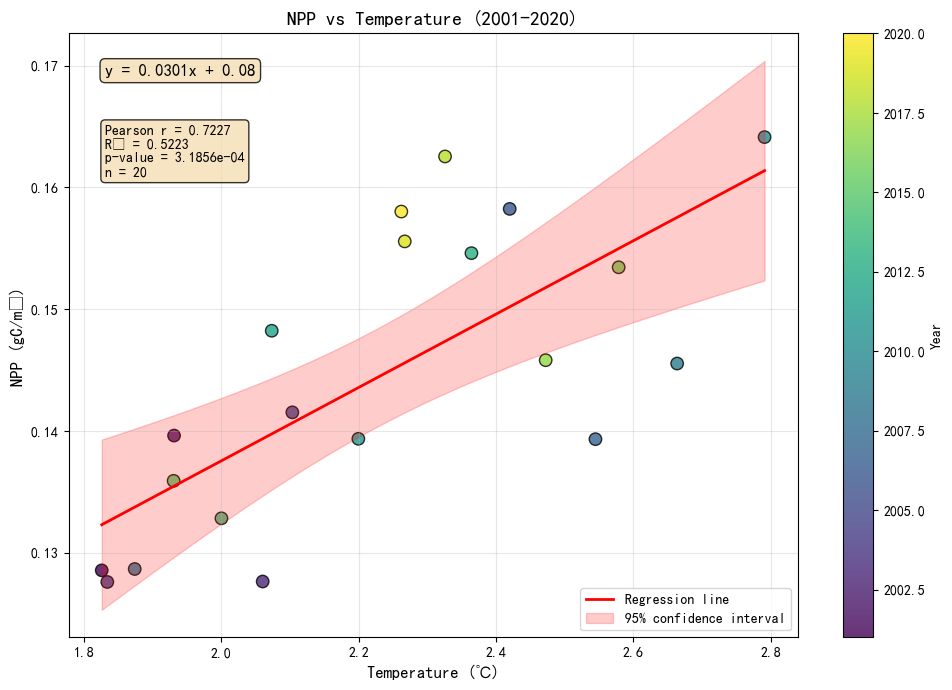


NPP vs Temperature (2001-2020)
回归方程: y = 0.0301x + 0.08
皮尔逊相关系数 r: 0.722735
决定系数 R²: 0.522345
p-value (相关性): 3.185571e-04
p-value (回归): 3.185571e-04
样本量: 20
相关性解读: 强正相关，显著



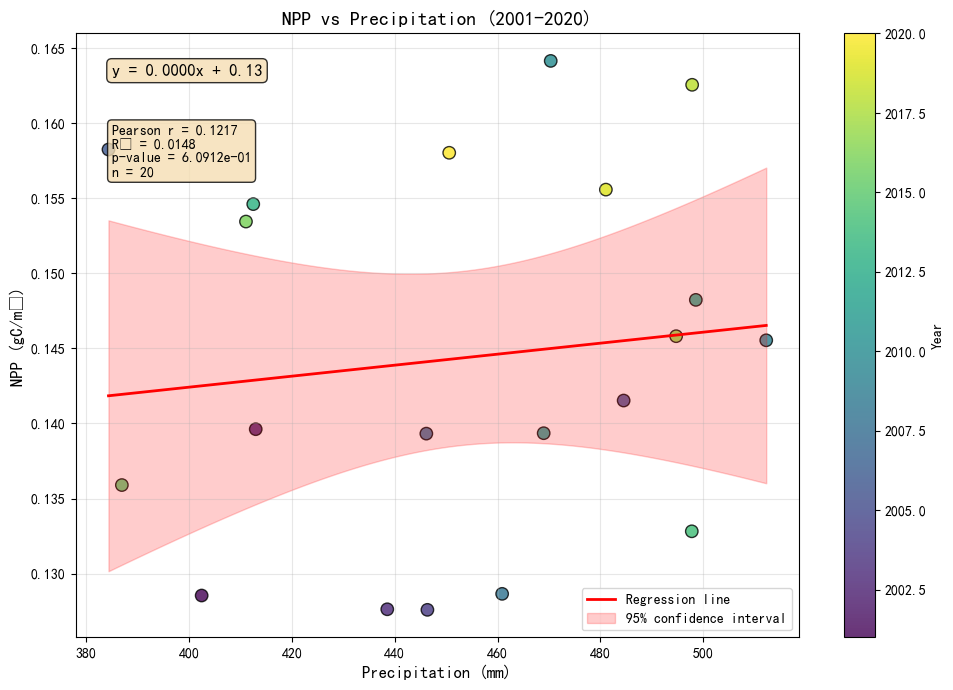


NPP vs Precipitation (2001-2020)
回归方程: y = 0.0000x + 0.13
皮尔逊相关系数 r: 0.121750
决定系数 R²: 0.014823
p-value (相关性): 6.091190e-01
p-value (回归): 6.091190e-01
样本量: 20
相关性解读: 极弱正相关，不显著



In [24]:
# 1. NPP vs 气温的相关性和线性回归分析
def correlation_regression_analysis(df, x_col, y_col, x_label, y_label, title):
    """
    分析两个变量之间的相关性和线性关系
    """
    x = df[x_col].values
    y = df[y_col].values
    
    # 相关系数
    r, p_corr = pearsonr(x, y)
    
    # 线性回归
    slope, intercept, r_value, p_reg, std_err = stats.linregress(x, y)
    
    # 预测值
    x_pred = np.linspace(x.min(), x.max(), 100)
    y_pred = slope * x_pred + intercept
    
    # 置信区间
    n = len(x)
    x_mean = np.mean(x)
    residuals = y - (slope * x + intercept)
    s_err = np.sqrt(np.sum(residuals**2) / (n - 2))
    t_val = stats.t.ppf(0.975, df=n-2)
    Sxx = np.sum((x - x_mean)**2)
    
    ci = t_val * s_err * np.sqrt(1/n + (x_pred - x_mean)**2 / Sxx)
    upper = y_pred + ci
    lower = y_pred - ci
    
    # 绘图
    fig, ax = plt.subplots(figsize=(10, 7))
    
    # 散点图，按年份着色
    scatter = ax.scatter(x, y, c=df['Year'], s=80, cmap='viridis', 
                        edgecolors='k', linewidth=1, alpha=0.8)
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('Year', fontsize=10)
    
    # 回归线
    ax.plot(x_pred, y_pred, 'r-', linewidth=2, label='Regression line')
    
    # 置信区间
    ax.fill_between(x_pred, lower, upper, color='red', alpha=0.2, 
                    label="95% confidence interval")
    
    # 标注统计信息
    equation = f'y = {slope:.4f}x + {intercept:.2f}'
    stats_text = f'Pearson r = {r:.4f}\nR² = {r_value**2:.4f}\np-value = {p_reg:.4e}\nn = {n}'
    
    ax.text(0.05, 0.95, equation, transform=ax.transAxes, 
            fontsize=12, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    ax.text(0.05, 0.85, stats_text, transform=ax.transAxes, 
            fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    
    ax.set_xlabel(x_label, fontsize=12)
    ax.set_ylabel(y_label, fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 打印结果
    print(f"\n{'='*60}")
    print(f"{title}")
    print(f"{'='*60}")
    print(f"回归方程: {equation}")
    print(f"皮尔逊相关系数 r: {r:.6f}")
    print(f"决定系数 R²: {r_value**2:.6f}")
    print(f"p-value (相关性): {p_corr:.6e}")
    print(f"p-value (回归): {p_reg:.6e}")
    print(f"样本量: {n}")
    
    # 相关性解读
    if abs(r) < 0.3:
        strength = "极弱"
    elif abs(r) < 0.5:
        strength = "弱"
    elif abs(r) < 0.7:
        strength = "中等"
    elif abs(r) < 0.9:
        strength = "强"
    else:
        strength = "极强"
    
    direction = "正相关" if r > 0 else "负相关"
    significance = "显著" if p_corr < 0.05 else "不显著"
    
    print(f"相关性解读: {strength}{direction}，{significance}")
    print(f"{'='*60}\n")
    
    return {'r': r, 'slope': slope, 'intercept': intercept, 
            'r2': r_value**2, 'p': p_reg, 'n': n}


print("=" * 70)
print("三江源地区NPP与气候因子相关性分析")
print("=" * 70)

# 1. NPP vs 气温
result_temp_corr = correlation_regression_analysis(
    df, 'Temperature', 'NPP', 
    'Temperature (℃)', 'NPP (gC/m²)',
    'NPP vs Temperature (2001-2020)'
)

# 2. NPP vs 降水
result_precip_corr = correlation_regression_analysis(
    df, 'Precipitation', 'NPP', 
    'Precipitation (mm)', 'NPP (gC/m²)',
    'NPP vs Precipitation (2001-2020)'
)

C:\Users\23983\AppData\Local\Temp\ipykernel_15392\4142287315.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\4142287315.py:45: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.tight_layout()


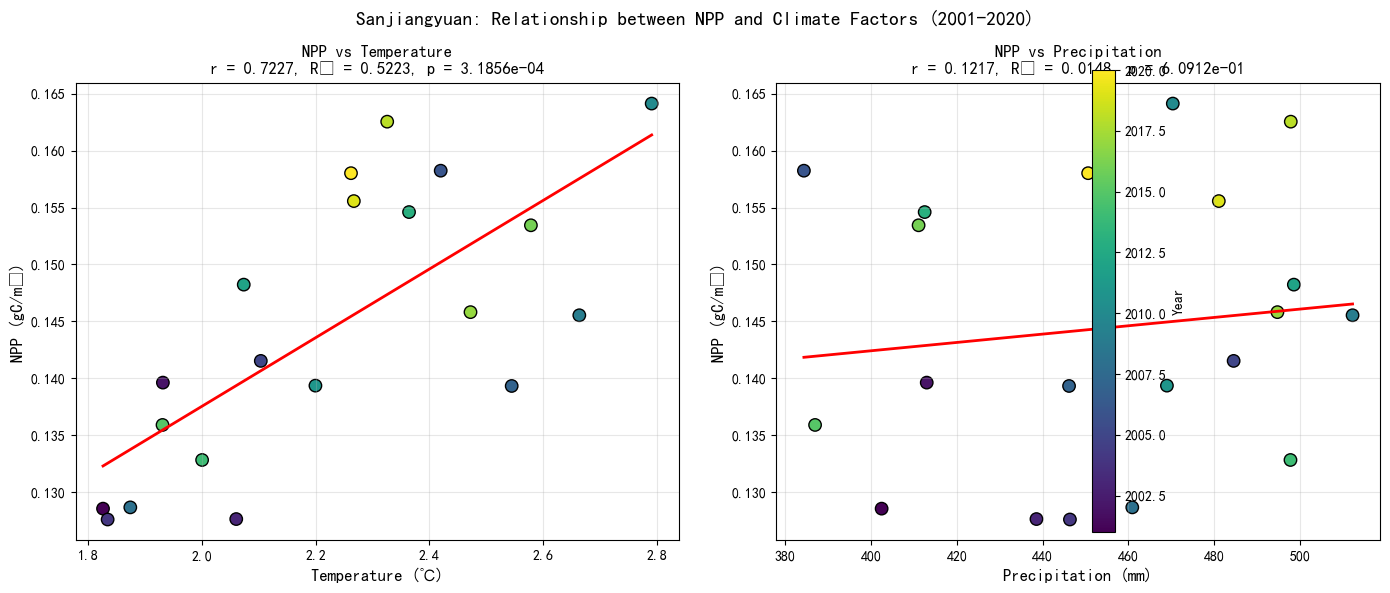

In [25]:
# 综合对比图：NPP与气温和降水的关系
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 子图1: NPP vs 气温
ax1 = axes[0]
x1 = df['Temperature'].values
y1 = df['NPP'].values

# 回归
slope1, intercept1, r1, p1, _ = stats.linregress(x1, y1)
x_line1 = np.linspace(x1.min(), x1.max(), 100)
y_line1 = slope1 * x_line1 + intercept1

ax1.scatter(x1, y1, s=80, c=df['Year'], cmap='viridis', edgecolors='k', linewidth=1)
ax1.plot(x_line1, y_line1, 'r-', linewidth=2)
ax1.set_xlabel('Temperature (℃)', fontsize=12)
ax1.set_ylabel('NPP (gC/m²)', fontsize=12)
ax1.set_title(f'NPP vs Temperature\nr = {r1:.4f}, R² = {r1**2:.4f}, p = {p1:.4e}', 
              fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)

# 子图2: NPP vs 降水
ax2 = axes[1]
x2 = df['Precipitation'].values
y2 = df['NPP'].values

# 回归
slope2, intercept2, r2, p2, _ = stats.linregress(x2, y2)
x_line2 = np.linspace(x2.min(), x2.max(), 100)
y_line2 = slope2 * x_line2 + intercept2

scatter = ax2.scatter(x2, y2, s=80, c=df['Year'], cmap='viridis', edgecolors='k', linewidth=1)
ax2.plot(x_line2, y_line2, 'r-', linewidth=2)
ax2.set_xlabel('Precipitation (mm)', fontsize=12)
ax2.set_ylabel('NPP (gC/m²)', fontsize=12)
ax2.set_title(f'NPP vs Precipitation\nr = {r2:.4f}, R² = {r2**2:.4f}, p = {p2:.4e}', 
              fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

cbar = plt.colorbar(scatter, ax=axes, orientation='vertical', pad=0.02)
cbar.set_label('Year', fontsize=10)

plt.suptitle('Sanjiangyuan: Relationship between NPP and Climate Factors (2001-2020)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


残差诊断分析


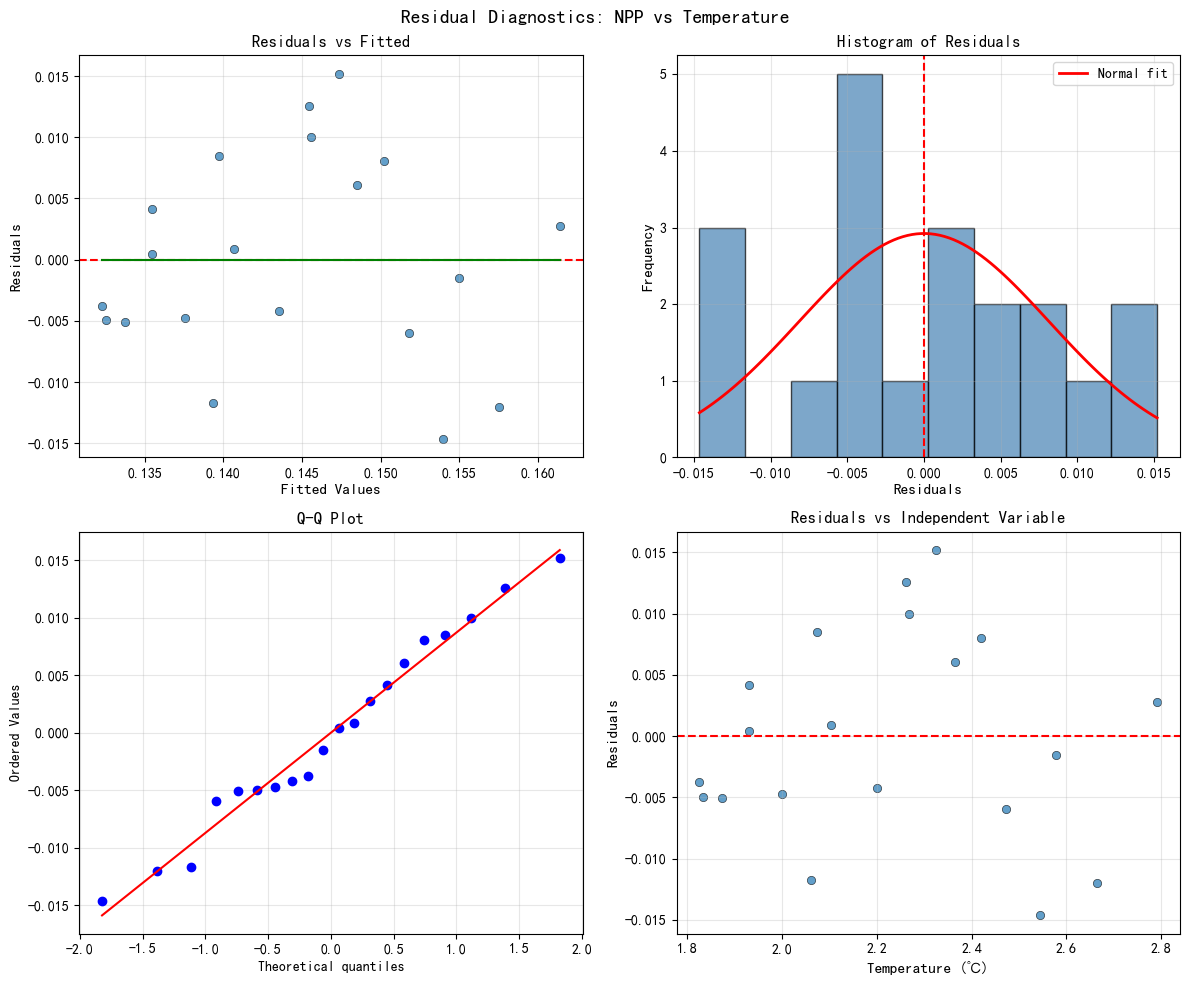


残差统计 - NPP vs Temperature:
  残差均值: 0.000000
  残差标准差: 0.008143
  残差偏度: 0.069998
  残差峰度: -0.857442
  Shapiro-Wilk正态性检验 p-value: 7.872380e-01


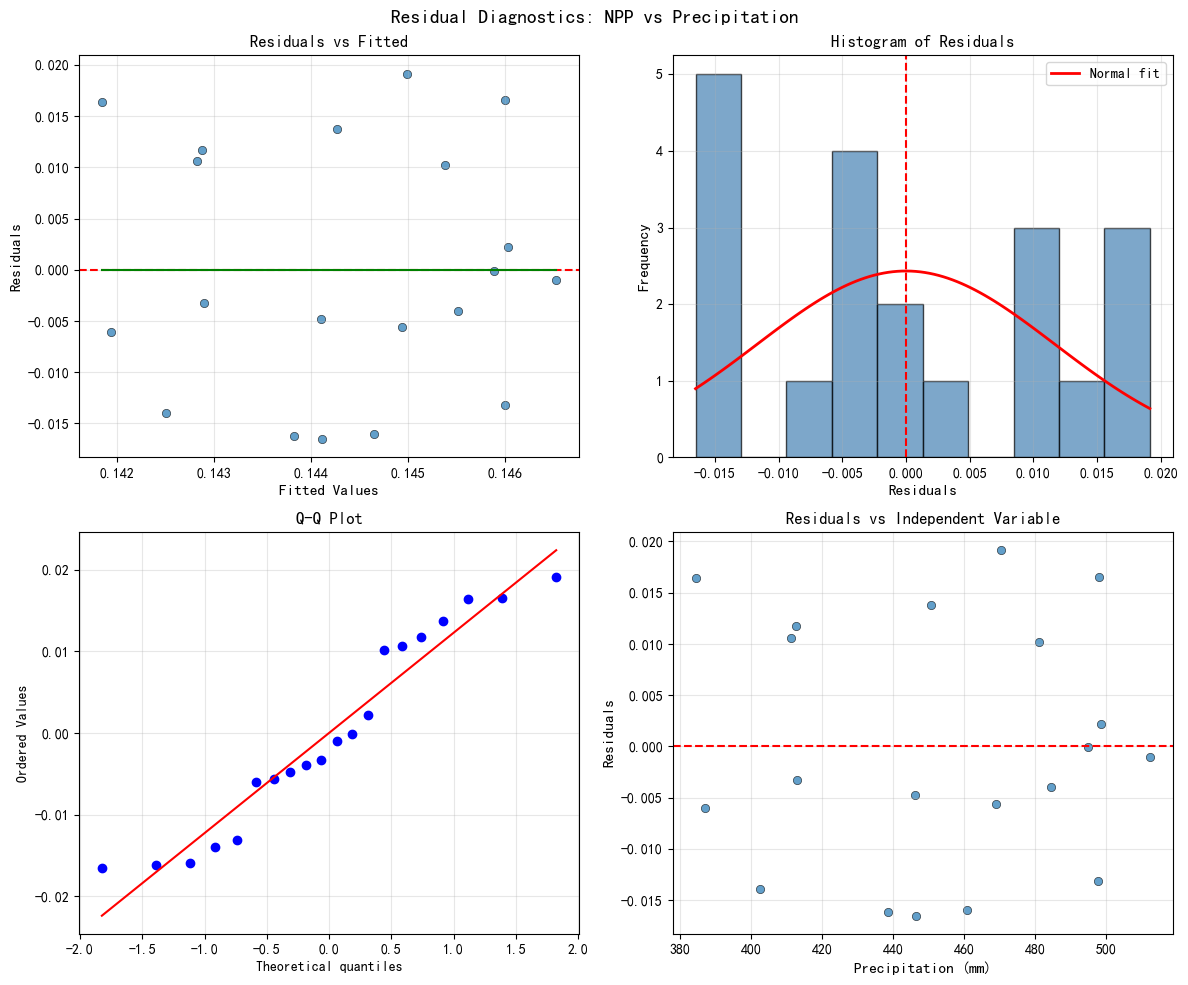


残差统计 - NPP vs Precipitation:
  残差均值: 0.000000
  残差标准差: 0.011695
  残差偏度: 0.124320
  残差峰度: -1.289192
  Shapiro-Wilk正态性检验 p-value: 1.043632e-01


In [27]:
# 残差分析：检查模型假设
def residual_diagnostic(df, x_col, y_col, x_label, title):
    """
    进行残差诊断
    """
    x = df[x_col].values
    y = df[y_col].values
    
    # 回归
    slope, intercept, _, _, _ = stats.linregress(x, y)
    y_pred = slope * x + intercept
    residuals = y - y_pred
    residuals_std = residuals / np.std(residuals)
    
    # 创建图形
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    fig.suptitle(f'Residual Diagnostics: {title}', fontsize=14, fontweight='bold')
    
    # 1. 残差 vs 拟合值
    axes[0, 0].scatter(y_pred, residuals, alpha=0.7, edgecolors='k', linewidth=0.5)
    axes[0, 0].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
    axes[0, 0].set_xlabel('Fitted Values', fontsize=11)
    axes[0, 0].set_ylabel('Residuals', fontsize=11)
    axes[0, 0].set_title('Residuals vs Fitted', fontsize=12)
    axes[0, 0].grid(True, alpha=0.3)
    
    # 添加趋势线
    z = np.polyfit(y_pred, residuals, 1)
    p = np.poly1d(z)
    axes[0, 0].plot(sorted(y_pred), p(sorted(y_pred)), 'green', linewidth=1.5)
    
    # 2. 残差直方图
    axes[0, 1].hist(residuals, bins=10, edgecolor='black', alpha=0.7, color='steelblue')
    axes[0, 1].axvline(x=0, color='red', linestyle='--', linewidth=1.5)
    axes[0, 1].set_xlabel('Residuals', fontsize=11)
    axes[0, 1].set_ylabel('Frequency', fontsize=11)
    axes[0, 1].set_title('Histogram of Residuals', fontsize=12)
    axes[0, 1].grid(True, alpha=0.3)
    
    # 添加正态分布拟合
    mu, std = np.mean(residuals), np.std(residuals)
    x_hist = np.linspace(residuals.min(), residuals.max(), 100)
    y_hist = stats.norm.pdf(x_hist, mu, std) * len(residuals) * (residuals.max() - residuals.min()) / 10
    axes[0, 1].plot(x_hist, y_hist, 'r-', linewidth=2, label='Normal fit')
    axes[0, 1].legend()
    
    # 3. Q-Q图
    stats.probplot(residuals, dist="norm", plot=axes[1, 0])
    axes[1, 0].set_title('Q-Q Plot', fontsize=12)
    axes[1, 0].grid(True, alpha=0.3)
    
    # 4. 残差 vs 自变量
    axes[1, 1].scatter(x, residuals, alpha=0.7, edgecolors='k', linewidth=0.5)
    axes[1, 1].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
    axes[1, 1].set_xlabel(x_label, fontsize=11)
    axes[1, 1].set_ylabel('Residuals', fontsize=11)
    axes[1, 1].set_title('Residuals vs Independent Variable', fontsize=12)
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 打印统计信息
    print(f"\n残差统计 - {title}:")
    print(f"  残差均值: {np.mean(residuals):.6f}")
    print(f"  残差标准差: {np.std(residuals):.6f}")
    print(f"  残差偏度: {stats.skew(residuals):.6f}")
    print(f"  残差峰度: {stats.kurtosis(residuals):.6f}")
    print(f"  Shapiro-Wilk正态性检验 p-value: {stats.shapiro(residuals)[1]:.6e}")


# 残差诊断
print("\n" + "=" * 70)
print("残差诊断分析")
print("=" * 70)

residual_diagnostic(df, 'Temperature', 'NPP', 'Temperature (℃)', 'NPP vs Temperature')

residual_diagnostic(df, 'Precipitation', 'NPP', 'Precipitation (mm)', 'NPP vs Precipitation')

In [28]:
# 结果汇总表
print("\n" + "=" * 80)
print("三江源地区NPP与气候因子相关性分析结果汇总")
print("=" * 80)

summary_df = pd.DataFrame({
    '关系': ['NPP vs 气温', 'NPP vs 降水'],
    '相关系数 r': [result_temp_corr['r'], result_precip_corr['r']],
    'R²': [result_temp_corr['r2'], result_precip_corr['r2']],
    '回归方程斜率': [result_temp_corr['slope'], result_precip_corr['slope']],
    'p-value': [result_temp_corr['p'], result_precip_corr['p']],
    '样本量': [result_temp_corr['n'], result_precip_corr['n']],
    '相关性强度': ['强' if abs(result_temp_corr['r']) > 0.7 else 
                 '中等' if abs(result_temp_corr['r']) > 0.5 else 
                 '弱' if abs(result_temp_corr['r']) > 0.3 else '极弱',
                 '强' if abs(result_precip_corr['r']) > 0.7 else 
                 '中等' if abs(result_precip_corr['r']) > 0.5 else 
                 '弱' if abs(result_precip_corr['r']) > 0.3 else '极弱'],
    '显著性': ['显著' if result_temp_corr['p'] < 0.05 else '不显著',
             '显著' if result_precip_corr['p'] < 0.05 else '不显著']
})

print(summary_df.to_string(index=False))


三江源地区NPP与气候因子相关性分析结果汇总
       关系   相关系数 r       R²   回归方程斜率  p-value  样本量 相关性强度 显著性
NPP vs 气温 0.722735 0.522345 0.030139 0.000319   20     强  显著
NPP vs 降水 0.121750 0.014823 0.000037 0.609119   20    极弱 不显著


正在读取数据...


C:\Users\23983\AppData\Local\Temp\ipykernel_15392\3274137687.py:95: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(x, y, c=kwargs.get('color', 'steelblue'),
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\3274137687.py:95: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(x, y, c=kwargs.get('color', 'steelblue'),
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\3274137687.py:95: UserWa

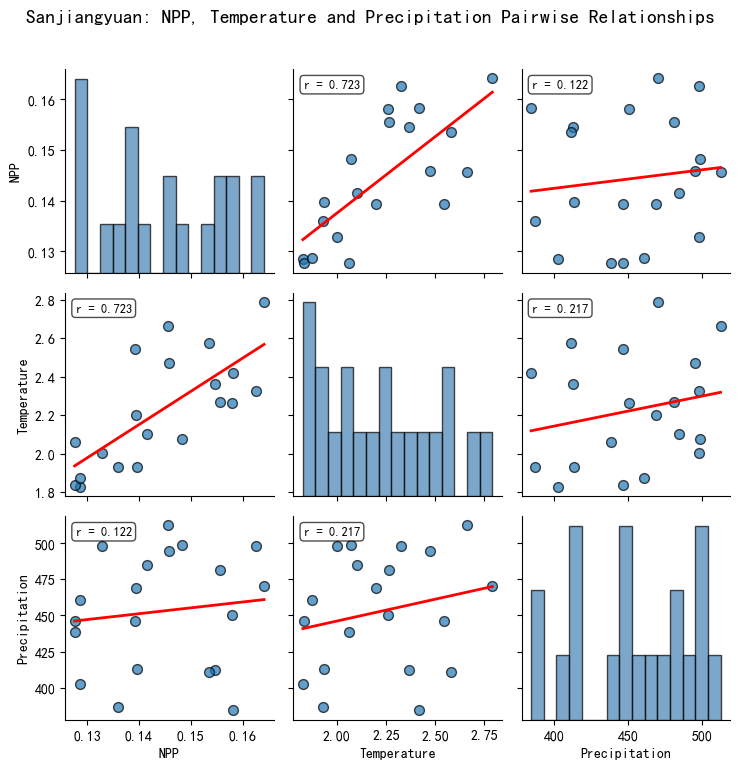

In [34]:
#为三江源地区的NPP、降水和气温数据绘制3×3的矩阵图
import os
import numpy as np
import rasterio
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 数据路径
base_path = './data/SanJiangYuan'
npp_path = os.path.join(base_path, 'NPP')
temp_path = os.path.join(base_path, 'Temperature')
precip_path = os.path.join(base_path, 'Precipitation')

# 获取年份列表
years = list(range(2001, 2021))

# 读取数据函数
def read_raster_mean(data_path, year, var_type):
    """
    读取栅格数据并计算均值
    var_type: 'npp', 'temp', 'precip'
    """
    if var_type == 'npp':
        filename = f"NPP_{year}.tif"
    elif var_type == 'temp':
        filename = f"tmp_{year}.tif"
    elif var_type == 'precip':
        filename = f"pre_{year}.tif"
    else:
        return np.nan
    
    filepath = os.path.join(data_path, filename)
    
    if not os.path.exists(filepath):
        print(f"文件不存在: {filepath}")
        return np.nan
    
    with rasterio.open(filepath) as src:
        data = src.read(1)
        # 只计算有效值
        valid_data = data[(data != src.nodata) & (~np.isnan(data))]
        if len(valid_data) == 0:
            return np.nan
        return np.mean(valid_data)

# 读取各年数据
npp_vals = []
temp_vals = []
precip_vals = []

print("正在读取数据...")
for year in years:
    npp = read_raster_mean(npp_path, year, 'npp')
    temp = read_raster_mean(temp_path, year, 'temp')
    precip = read_raster_mean(precip_path, year, 'precip')
    
    npp_vals.append(npp)
    temp_vals.append(temp)
    precip_vals.append(precip)
    

# 创建数据框
df = pd.DataFrame({
    'Year': years,
    'NPP': npp_vals,
    'Temperature': temp_vals,
    'Precipitation': precip_vals
})

# 移除缺失值
df_clean = df.dropna()

# 创建相关系数计算函数
def corr_func(x, y, **kwargs):
    """计算相关系数并显示在图上"""
    r, p = pearsonr(x, y)
    ax = plt.gca()
    ax.annotate(f'r = {r:.3f}\np = {p:.3e}', 
                xy=(0.1, 0.9), xycoords=ax.transAxes,
                fontsize=10, ha='left', va='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# 创建散点图函数（带回归线）
def scatter_with_regression(x, y, **kwargs):
    """绘制散点图和回归线"""
    ax = plt.gca()
    
    # 散点图，按年份着色
    scatter = ax.scatter(x, y, c=kwargs.get('color', 'steelblue'), 
                        alpha=0.7, edgecolors='k', s=50)
    
    # 添加回归线
    z = np.polyfit(x, y, 1)
    p = np.poly1d(z)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, p(x_line), 'r-', linewidth=2)
    
    # 计算相关系数
    r, p_val = pearsonr(x, y)
    ax.annotate(f'r = {r:.3f}', xy=(0.05, 0.95), xycoords=ax.transAxes,
                fontsize=9, ha='left', va='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

# 创建对角线直方图函数
def diag_hist(data, **kwargs):
    """绘制对角线上的直方图"""
    ax = plt.gca()
    ax.hist(data, bins=15, edgecolor='black', alpha=0.7, color='steelblue')
    ax.set_xlabel('')
    ax.set_ylabel('')

# 创建pairplot
# 选择需要绘制的列
vars_to_plot = ['NPP', 'Temperature', 'Precipitation']

# 创建pairplot
g = sns.PairGrid(df_clean[vars_to_plot], diag_sharey=False)
g.map_upper(scatter_with_regression)
g.map_lower(scatter_with_regression)
g.map_diag(diag_hist)

# 添加标题
plt.suptitle('Sanjiangyuan: NPP, Temperature and Precipitation Pairwise Relationships', 
             fontsize=14, fontweight='bold', y=1.02)

# 显示图形
plt.tight_layout()
plt.show()


#### 3.构建 NPP（因变量）和气温、降水（自变量）间的多元线性回归关系

In [36]:
# 安装 statsmodels
!pip install statsmodels -q

In [38]:
#构建 NPP（因变量）和气温、降水（自变量）间的多元线性回归关系
import os
import numpy as np
import rasterio
import pandas as pd
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 数据路径
base_path = './data/SanJiangYuan'
npp_path = os.path.join(base_path, 'NPP')
temp_path = os.path.join(base_path, 'Temperature')
precip_path = os.path.join(base_path, 'Precipitation')

# 获取年份列表
years = list(range(2001, 2021))

# 读取数据函数
def read_raster_mean(data_path, year, var_type):
    """
    读取栅格数据并计算均值
    var_type: 'npp', 'temp', 'precip'
    """
    if var_type == 'npp':
        filename = f"NPP_{year}.tif"
    elif var_type == 'temp':
        filename = f"tmp_{year}.tif"
    elif var_type == 'precip':
        filename = f"pre_{year}.tif"
    else:
        return np.nan
    
    filepath = os.path.join(data_path, filename)
    
    if not os.path.exists(filepath):
        print(f"文件不存在: {filepath}")
        return np.nan
    
    with rasterio.open(filepath) as src:
        data = src.read(1)
        valid_data = data[(data != src.nodata) & (~np.isnan(data))]
        if len(valid_data) == 0:
            return np.nan
        return np.mean(valid_data)

# 读取各年数据
npp_vals = []
temp_vals = []
precip_vals = []

print("正在读取数据...")
for year in years:
    npp = read_raster_mean(npp_path, year, 'npp')
    temp = read_raster_mean(temp_path, year, 'temp')
    precip = read_raster_mean(precip_path, year, 'precip')
    
    npp_vals.append(npp)
    temp_vals.append(temp)
    precip_vals.append(precip)
    
    print(f"{year}: NPP={npp:.2f}, Temp={temp:.2f}℃, Precip={precip:.1f}mm")

# 创建数据框
df = pd.DataFrame({
    'Year': years,
    'NPP': npp_vals,
    'Temperature': temp_vals,
    'Precipitation': precip_vals
})

# 移除缺失值
df_clean = df.dropna()
print(f"\n有效数据点: {len(df_clean)}")
print(df_clean.head())

正在读取数据...
2001: NPP=0.13, Temp=1.83℃, Precip=402.5mm
2002: NPP=0.14, Temp=1.93℃, Precip=413.0mm
2003: NPP=0.13, Temp=2.06℃, Precip=438.6mm
2004: NPP=0.13, Temp=1.83℃, Precip=446.4mm
2005: NPP=0.14, Temp=2.10℃, Precip=484.5mm
2006: NPP=0.16, Temp=2.42℃, Precip=384.3mm
2007: NPP=0.14, Temp=2.54℃, Precip=446.1mm
2008: NPP=0.13, Temp=1.87℃, Precip=460.9mm
2009: NPP=0.15, Temp=2.66℃, Precip=512.3mm
2010: NPP=0.16, Temp=2.79℃, Precip=470.3mm
2011: NPP=0.14, Temp=2.20℃, Precip=469.0mm
2012: NPP=0.15, Temp=2.07℃, Precip=498.6mm
2013: NPP=0.15, Temp=2.36℃, Precip=412.5mm
2014: NPP=0.13, Temp=2.00℃, Precip=497.8mm
2015: NPP=0.14, Temp=1.93℃, Precip=386.9mm
2016: NPP=0.15, Temp=2.58℃, Precip=411.1mm
2017: NPP=0.15, Temp=2.47℃, Precip=494.7mm
2018: NPP=0.16, Temp=2.33℃, Precip=497.8mm
2019: NPP=0.16, Temp=2.27℃, Precip=481.1mm
2020: NPP=0.16, Temp=2.26℃, Precip=450.6mm

有效数据点: 20
   Year       NPP  Temperature  Precipitation
0  2001  0.128544     1.825920     402.451447
1  2002  0.139618     1.931

In [39]:
# 多元线性回归分析
def multiple_linear_regression(df, target, predictors):
    """
    多元线性回归分析
    """
    X = df[predictors].copy()
    y = df[target].copy()
    
    # 添加截距项
    X = sm.add_constant(X)
    
    # 拟合模型
    model = sm.OLS(y, X).fit()
    
    return model, X

# 定义预测变量
predictors = ['Temperature', 'Precipitation']

# 构建多元线性回归模型
print("=" * 80)
print("三江源地区 NPP 与气温、降水的多元线性回归分析")
print("=" * 80)

model, X = multiple_linear_regression(df_clean, 'NPP', predictors)

# 打印模型摘要
print("\n模型摘要:")
print(model.summary())

# 提取关键结果
print("\n" + "=" * 60)
print("关键结果汇总")
print("=" * 60)
print(f"回归方程: NPP = {model.params['const']:.4f} + {model.params['Temperature']:.4f} × 气温 + {model.params['Precipitation']:.4f} × 降水")
print(f"R² (决定系数): {model.rsquared:.6f}")
print(f"调整后 R²: {model.rsquared_adj:.6f}")
print(f"F统计量: {model.fvalue:.4f}")
print(f"F检验 p值: {model.f_pvalue:.6e}")
print(f"AIC: {model.aic:.2f}")
print(f"BIC: {model.bic:.2f}")

三江源地区 NPP 与气温、降水的多元线性回归分析

模型摘要:
                            OLS Regression Results                            
Dep. Variable:                    NPP   R-squared:                       0.524
Model:                            OLS   Adj. R-squared:                  0.468
Method:                 Least Squares   F-statistic:                     9.344
Date:                Thu, 07 May 2026   Prob (F-statistic):            0.00183
Time:                        17:20:49   Log-Likelihood:                 67.860
No. Observations:                  20   AIC:                            -129.7
Df Residuals:                      17   BIC:                            -126.7
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const        

In [40]:
# 变量显著性检验
print("\n" + "=" * 60)
print("变量显著性检验")
print("=" * 60)

for var in ['const', 'Temperature', 'Precipitation']:
    p_value = model.pvalues[var]
    coef = model.params[var]
    std_err = model.bse[var]
    t_val = model.tvalues[var]
    
    significance = "显著" if p_value < 0.05 else "不显著"
    print(f"\n{var}:")
    print(f"  系数 = {coef:.6f}")
    print(f"  标准误 = {std_err:.6f}")
    print(f"  t值 = {t_val:.4f}")
    print(f"  p值 = {p_value:.6e}")
    print(f"  显著性: {significance}")


变量显著性检验

const:
  系数 = 0.081558
  标准误 = 0.025330
  t值 = 3.2198
  p值 = 5.028491e-03
  显著性: 显著

Temperature:
  系数 = 0.030475
  标准误 = 0.007151
  t值 = 4.2614
  p值 = 5.270664e-04
  显著性: 显著

Precipitation:
  系数 = -0.000011
  标准误 = 0.000052
  t值 = -0.2159
  p值 = 8.316439e-01
  显著性: 不显著


In [41]:
# 多重共线性检验 (VIF)
def calculate_vif(df, predictors):
    """计算方差膨胀因子"""
    X = df[predictors].copy()
    X = sm.add_constant(X)
    
    vif_data = pd.DataFrame()
    vif_data["variable"] = X.columns
    vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return vif_data

print("\n" + "=" * 60)
print("多重共线性检验 (VIF)")
print("=" * 60)

vif_result = calculate_vif(df_clean, predictors)
print(vif_result)

# 判断共线性
for idx, row in vif_result.iterrows():
    if row['variable'] != 'const':
        vif = row['VIF']
        if vif > 10:
            print(f"  ⚠️ {row['variable']}: VIF={vif:.2f} > 10，存在严重共线性")
        elif vif > 5:
            print(f"  ⚠️ {row['variable']}: VIF={vif:.2f} > 5，存在中等共线性")
        else:
            print(f"  ✓ {row['variable']}: VIF={vif:.2f} < 5，无显著共线性")


多重共线性检验 (VIF)
        variable         VIF
0          const  164.941175
1    Temperature    1.049543
2  Precipitation    1.049543
  ✓ Temperature: VIF=1.05 < 5，无显著共线性
  ✓ Precipitation: VIF=1.05 < 5，无显著共线性


C:\Users\23983\AppData\Local\Temp\ipykernel_15392\4101686485.py:29: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  plt.tight_layout()
c:\Users\23983\AppData\Roaming\mamba\envs\pygeo\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 178 (\N{SUPERSCRIPT TWO}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


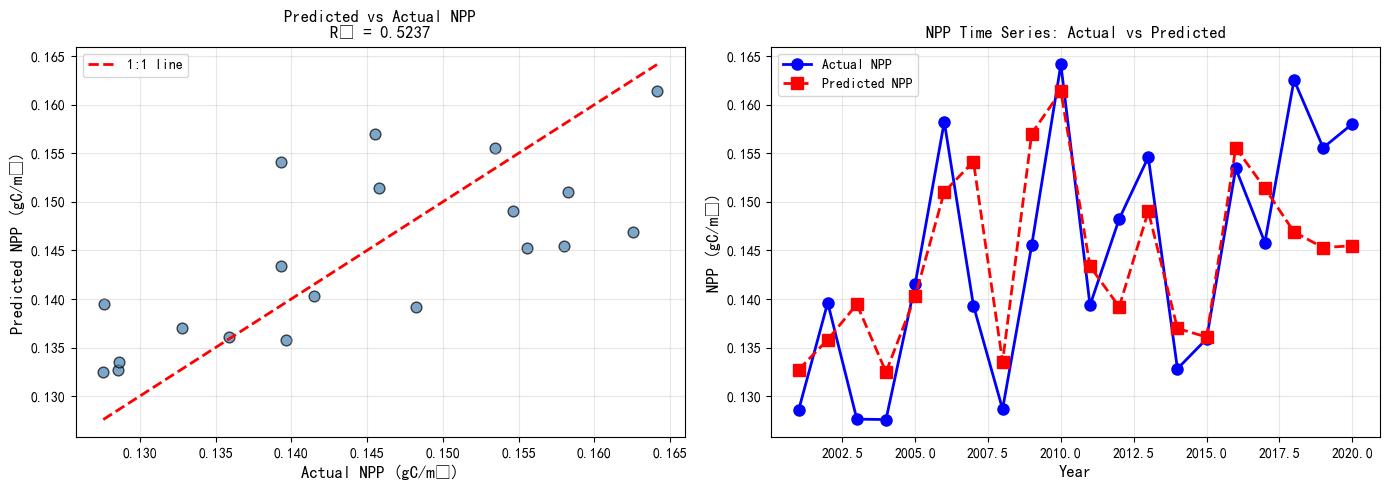

In [43]:
# 预测值与实际值对比图
y_pred = model.predict(X)
y_actual = df_clean['NPP']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 子图1: 预测值 vs 实际值散点图
ax1 = axes[0]
ax1.scatter(y_actual, y_pred, alpha=0.7, s=60, c='steelblue', edgecolors='k')
ax1.plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], 
         'r--', linewidth=2, label='1:1 line')
ax1.set_xlabel('Actual NPP (gC/m²)', fontsize=12)
ax1.set_ylabel('Predicted NPP (gC/m²)', fontsize=12)
ax1.set_title(f'Predicted vs Actual NPP\nR² = {model.rsquared:.4f}', fontsize=12)
ax1.legend()
ax1.grid(True, alpha=0.3)

# 子图2: 时间序列（实际值 vs 预测值）
ax2 = axes[1]
years_clean = df_clean['Year'].values
ax2.plot(years_clean, y_actual, 'o-', label='Actual NPP', linewidth=2, markersize=8, color='blue')
ax2.plot(years_clean, y_pred, 's--', label='Predicted NPP', linewidth=2, markersize=8, color='red')
ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('NPP (gC/m²)', fontsize=12)
ax2.set_title('NPP Time Series: Actual vs Predicted', fontsize=12)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### 4.实现三江源地区NPP与气温和降水间的偏相关分析并绘图显示结果

In [47]:
import os
import numpy as np
import rasterio
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.linalg import inv
import seaborn as sns

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 数据路径
base_path = './data/SanJiangYuan'
npp_path = os.path.join(base_path, 'NPP')
temp_path = os.path.join(base_path, 'Temperature')
precip_path = os.path.join(base_path, 'Precipitation')

# 获取年份列表
years = list(range(2001, 2021))

# 读取数据函数
def read_raster_mean(data_path, year, var_type):
    """
    读取栅格数据并计算均值
    var_type: 'npp', 'temp', 'precip'
    """
    if var_type == 'npp':
        filename = f"NPP_{year}.tif"
    elif var_type == 'temp':
        filename = f"tmp_{year}.tif"
    elif var_type == 'precip':
        filename = f"pre_{year}.tif"
    else:
        return np.nan
    
    filepath = os.path.join(data_path, filename)
    
    if not os.path.exists(filepath):
        print(f"文件不存在: {filepath}")
        return np.nan
    
    with rasterio.open(filepath) as src:
        data = src.read(1)
        valid_data = data[(data != src.nodata) & (~np.isnan(data))]
        if len(valid_data) == 0:
            return np.nan
        return np.mean(valid_data)

# 读取各年数据
npp_vals = []
temp_vals = []
precip_vals = []

for year in years:
    npp = read_raster_mean(npp_path, year, 'npp')
    temp = read_raster_mean(temp_path, year, 'temp')
    precip = read_raster_mean(precip_path, year, 'precip')
    
    npp_vals.append(npp)
    temp_vals.append(temp)
    precip_vals.append(precip)
    

# 创建数据框，移除缺失值
df = pd.DataFrame({
    'Year': years,
    'NPP': npp_vals,
    'Temperature': temp_vals,
    'Precipitation': precip_vals
}).dropna()

# 偏相关系数计算函数
def partial_correlation(x, y, z):
    """
    计算偏相关系数（控制z的影响）
    x, y, z: 三个变量的数据序列
    
    返回: 偏相关系数r和p值
    """
    # 方法1: 使用残差法
    # 1. 用y对z回归，得到残差（去除z的影响）
    slope_yz, intercept_yz, _, _, _ = stats.linregress(z, y)
    y_residual = y - (slope_yz * z + intercept_yz)
    
    # 2. 用x对z回归，得到残差
    slope_xz, intercept_xz, _, _, _ = stats.linregress(z, x)
    x_residual = x - (slope_xz * z + intercept_xz)
    
    # 3. 计算残差之间的相关系数
    r, p = stats.pearsonr(x_residual, y_residual)
    
    return r, p


def partial_correlation_formula(x, y, z):
    """
    使用公式法计算偏相关系数
    r_xy.z = (r_xy - r_xz * r_yz) / sqrt((1 - r_xz^2) * (1 - r_yz^2))
    """
    r_xy, p_xy = stats.pearsonr(x, y)
    r_xz, p_xz = stats.pearsonr(x, z)
    r_yz, p_yz = stats.pearsonr(y, z)
    
    # 避免除零
    denominator = np.sqrt((1 - r_xz**2) * (1 - r_yz**2))
    if denominator == 0:
        return np.nan, np.nan
    
    r = (r_xy - r_xz * r_yz) / denominator
    
    # 计算偏相关的p值（近似）
    df = len(x) - 3  # 自由度 = n - 3
    if df > 0:
        t = r * np.sqrt(df / (1 - r**2)) if abs(r) < 1 else 0
        p = 2 * (1 - stats.t.cdf(abs(t), df))
    else:
        p = np.nan
    
    return r, p


# 计算简单相关系数
print("=" * 70)
print("简单相关系数矩阵")
print("=" * 70)

corr_matrix = df[['NPP', 'Temperature', 'Precipitation']].corr()
print(corr_matrix.round(4))

# 计算偏相关系数
print("\n" + "=" * 70)
print("偏相关系数分析")
print("=" * 70)

# 1. NPP与气温的偏相关（控制降水影响）
r_npp_temp_precip, p_npp_temp_precip = partial_correlation(
    df['NPP'].values, df['Temperature'].values, df['Precipitation'].values
)

# 2. NPP与降水的偏相关（控制气温影响）
r_npp_precip_temp, p_npp_precip_temp = partial_correlation(
    df['NPP'].values, df['Precipitation'].values, df['Temperature'].values
)

# 3. 气温与降水的偏相关（控制NPP影响）
r_temp_precip_npp, p_temp_precip_npp = partial_correlation(
    df['Temperature'].values, df['Precipitation'].values, df['NPP'].values
)

print(f"\n偏相关系数 (控制降水后 NPP与气温):")
print(f"  r = {r_npp_temp_precip:.6f}")
print(f"  p = {p_npp_temp_precip:.6e}")
print(f"  显著性: {'显著' if p_npp_temp_precip < 0.05 else '不显著'}")

print(f"\n偏相关系数 (控制气温后 NPP与降水):")
print(f"  r = {r_npp_precip_temp:.6f}")
print(f"  p = {p_npp_precip_temp:.6e}")
print(f"  显著性: {'显著' if p_npp_precip_temp < 0.05 else '不显著'}")

print(f"\n偏相关系数 (控制NPP后 气温与降水):")
print(f"  r = {r_temp_precip_npp:.6f}")
print(f"  p = {p_temp_precip_npp:.6e}")
print(f"  显著性: {'显著' if p_temp_precip_npp < 0.05 else '不显著'}")


简单相关系数矩阵
                  NPP  Temperature  Precipitation
NPP            1.0000       0.7227         0.1217
Temperature    0.7227       1.0000         0.2173
Precipitation  0.1217       0.2173         1.0000

偏相关系数分析

偏相关系数 (控制降水后 NPP与气温):
  r = 0.718668
  p = 3.572009e-04
  显著性: 显著

偏相关系数 (控制气温后 NPP与降水):
  r = -0.052289
  p = 8.266998e-01
  显著性: 不显著

偏相关系数 (控制NPP后 气温与降水):
  r = 0.188448
  p = 4.262261e-01
  显著性: 不显著


正在读取并堆叠栅格数据...
正在进行逐像元偏相关分析...


C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1339285715.py:36: RuntimeWarning: Mean of empty slice
  x_mean = np.nanmean(x, axis=0)
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1339285715.py:37: RuntimeWarning: Mean of empty slice
  y_mean = np.nanmean(y, axis=0)
C:\Users\23983\AppData\Local\Temp\ipykernel_15392\1339285715.py:101: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.18, 1, 0.95])


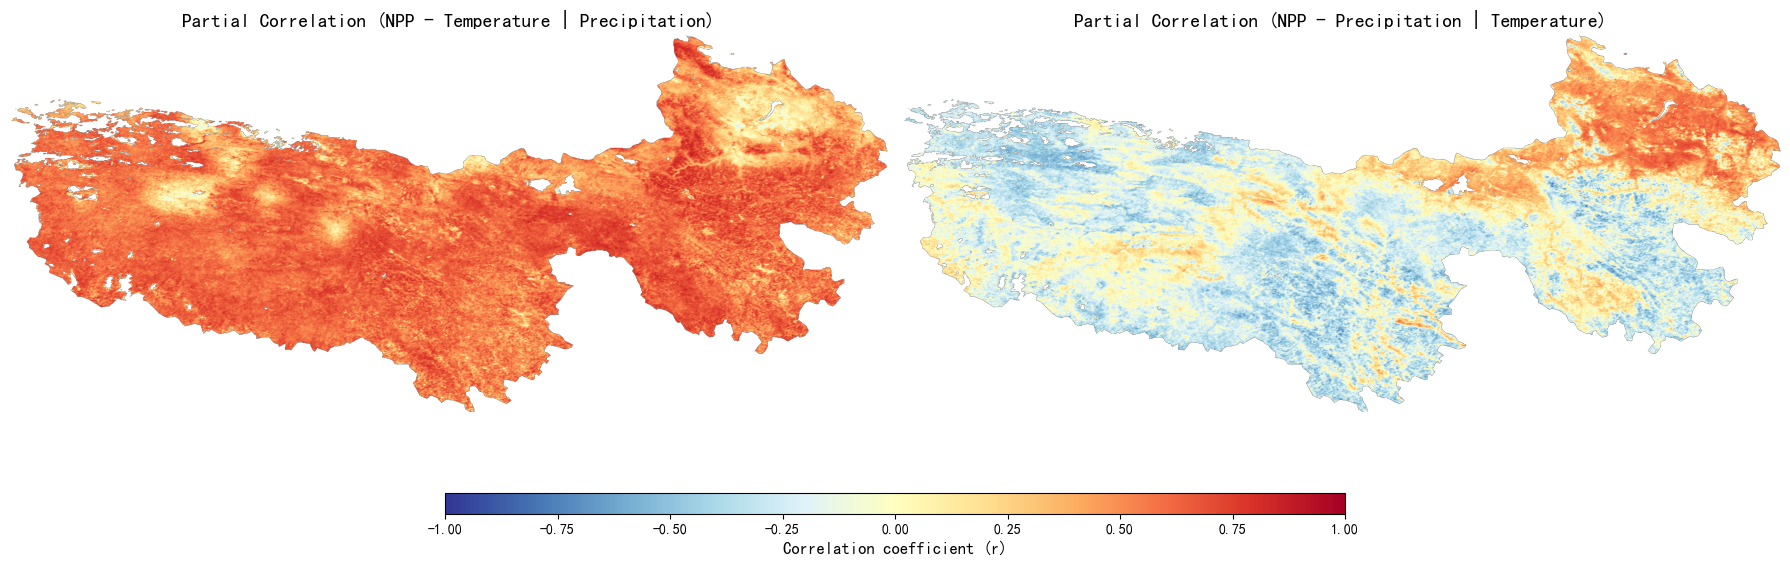

In [ ]:
import os
import glob
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# --- 1. 路径设置 ---
base_path = './data/SanJiangYuan'  
npp_path = os.path.join(base_path, 'NPP')
temp_path = os.path.join(base_path, 'Temperature')
precip_path = os.path.join(base_path, 'Precipitation')

# --- 2. 数据读取函数（保留空间结构） ---
def load_data_stack(folder, prefix, years):
    """
    将多年数据读取并堆叠为 (Years, Height, Width) 的三维数组
    """
    stack = []
    meta = None
    for year in years:
        # 根据你的描述：气温为 tmp_20xx.tif，降水为 pre_20xx.tif
        file_path = os.path.join(folder, f"{prefix}_{year}.tif")
        with rasterio.open(file_path) as src:
            data = src.read(1).astype(np.float32)
            # 处理无效值：将 nodata 设为 NaN
            data[data == src.nodata] = np.nan
            stack.append(data)
            if meta is None:
                meta = src.profile
    return np.array(stack), meta

# --- 3. 核心计算函数：偏相关系数 ---
def get_pixel_correlation(x, y):
    """计算两个三维数组在时间轴上的相关系数"""
    x_mean = np.nanmean(x, axis=0)
    y_mean = np.nanmean(y, axis=0)
    
    # 按照 Pearson 相关系数公式计算
    term_x = x - x_mean
    term_y = y - y_mean
    
    num = np.nansum(term_x * term_y, axis=0)
    den = np.sqrt(np.nansum(term_x**2, axis=0) * np.nansum(term_y**2, axis=0))
    
    # 避免分母为0的警告
    result = np.divide(num, den, out=np.zeros_like(num), where=den!=0)
    result[np.all(np.isnan(x), axis=0)] = np.nan # 保持掩膜
    return result

def calculate_partial_corr(y, x1, x2):
    """
    计算控制 x2 情况下，y 与 x1 的偏相关系数
    公式: r_yx1.x2 = (r_yx1 - r_yx2 * r_x1x2) / sqrt((1-r_yx2^2)*(1-r_x1x2^2))
    """
    r_yx1 = get_pixel_correlation(y, x1)
    r_yx2 = get_pixel_correlation(y, x2)
    r_x1x2 = get_pixel_correlation(x1, x2)
    
    num = r_yx1 - (r_yx2 * r_x1x2)
    den = np.sqrt((1 - r_yx2**2) * (1 - r_x1x2**2))
    
    res = np.divide(num, den, out=np.zeros_like(num), where=den!=0)
    res[np.isnan(r_yx1)] = np.nan
    return res

# --- 4. 执行计算 ---
years = list(range(2001, 2021))
print("正在读取并堆叠栅格数据...")
npp_stack, meta = load_data_stack(npp_path, "NPP", years)
temp_stack, _ = load_data_stack(temp_path, "tmp", years)
prec_stack, _ = load_data_stack(precip_path, "pre", years)

print("正在进行逐像元偏相关分析...")
# 控制降水，计算 NPP 与 气温 的偏相关
p_corr_temp = calculate_partial_corr(npp_stack, temp_stack, prec_stack)
# 控制气温，计算 NPP 与 降水 的偏相关
p_corr_prec = calculate_partial_corr(npp_stack, prec_stack, temp_stack)

# --- 5. 结果绘图 ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 定义配色方案 (红-白-蓝)
cmap = plt.get_cmap('RdYlBu_r') 

# 子图1: NPP - Temperature
im1 = axes[0].imshow(p_corr_temp, cmap=cmap, vmin=-1, vmax=1)
axes[0].set_title("Partial Correlation (NPP - Temperature | Precipitation)", fontsize=14)
axes[0].axis('off')

# 子图2: NPP - Precipitation
im2 = axes[1].imshow(p_corr_prec, cmap=cmap, vmin=-1, vmax=1)
axes[1].set_title("Partial Correlation (NPP - Precipitation | Temperature)", fontsize=14)
axes[1].axis('off')

# 添加公用颜色条
cbar_ax = fig.add_axes([0.25, 0.15, 0.5, 0.03]) # [left, bottom, width, height]
cbar = fig.colorbar(im1, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Correlation coefficient (r)', fontsize=12)

plt.tight_layout(rect=[0, 0.18, 1, 0.95])
plt.show()
